Configuración general del Notebook para Dataset base único y folds

In [2]:
# ============================================================
# Configuración general e imports
# ============================================================
import os
import gc
import json
import math
import glob
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from tqdm import tqdm

# -----------------------------
# Semilla para reproducibilidad
# -----------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# -----------------------------
# Rutas principales
# -----------------------------
BASE_DRIVE = Path("C:\\Users\\olide\\Documents\\Maestría\\Dataset")

# CSVs de split externo + folds
SPLITS_DIR = BASE_DRIVE / "splits_cv_5fold"

TRAIN_OUTER_CSV = SPLITS_DIR / "train_outer_split.csv"
TEST_OUTER_CSV  = SPLITS_DIR / "test_outer_split.csv"

# Carpeta donde guardaremos el nuevo dataset base + índices
OUT_DIR = BASE_DRIVE / "OCT_base_cv5"

TRAIN_BASE_DIR = OUT_DIR / "train_outer"
TEST_BASE_DIR  = OUT_DIR / "test_outer"
INDICES_DIR    = OUT_DIR / "indices"
META_DIR       = OUT_DIR / "metadata"

# Crear carpetas de salida
for p in [OUT_DIR, TRAIN_BASE_DIR, TEST_BASE_DIR, INDICES_DIR, META_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Parámetros del preprocesamiento
# -----------------------------
IMG_SIZE = 512
ROI_MARGIN = 16
EPS = 1e-6

# Tamaño de shard para materialización base
# Ajustable según RAM/velocidad
SHARD_SIZE = 512

# -----------------------------
# Configuración de visualización
# -----------------------------
plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["image.cmap"] = "gray"


print("=" * 80)
print("✅ Entorno inicializado")
print(f"BASE_DRIVE     : {BASE_DRIVE}")
print(f"SPLITS_DIR     : {SPLITS_DIR}")
print(f"OUT_DIR        : {OUT_DIR}")
print(f"IMG_SIZE       : {IMG_SIZE}")
print(f"ROI_MARGIN     : {ROI_MARGIN}")
print(f"SHARD_SIZE     : {SHARD_SIZE}")
print("=" * 80)

✅ Entorno inicializado
BASE_DRIVE     : C:\Users\olide\Documents\Maestría\Dataset
SPLITS_DIR     : C:\Users\olide\Documents\Maestría\Dataset\splits_cv_5fold
OUT_DIR        : C:\Users\olide\Documents\Maestría\Dataset\OCT_base_cv5
IMG_SIZE       : 512
ROI_MARGIN     : 16
SHARD_SIZE     : 512


Carga y validación de splits / folds

In [3]:
# -----------------------------
# Verificar existencia de CSVs principales
# -----------------------------
assert TRAIN_OUTER_CSV.exists(), f"No existe: {TRAIN_OUTER_CSV}"
assert TEST_OUTER_CSV.exists(),  f"No existe: {TEST_OUTER_CSV}"

# -----------------------------
# Cargar splits externos
# -----------------------------
df_train_outer = pd.read_csv(TRAIN_OUTER_CSV)
df_test_outer  = pd.read_csv(TEST_OUTER_CSV)

# -----------------------------
# Detectar folds disponibles
# -----------------------------
fold_train_files = sorted(SPLITS_DIR.glob("fold_*_train.csv"))
fold_val_files   = sorted(SPLITS_DIR.glob("fold_*_val.csv"))

assert len(fold_train_files) > 0, "No se encontraron fold_*_train.csv"
assert len(fold_val_files) > 0,   "No se encontraron fold_*_val.csv"
assert len(fold_train_files) == len(fold_val_files), \
    "Número desigual de archivos train/val por fold"

# Extraer IDs de fold
fold_ids = sorted([
    int(p.stem.split("_")[1]) for p in fold_train_files
])

# -----------------------------
# Inspección rápida
# -----------------------------
print("=" * 90)
print("📂 ARCHIVOS DETECTADOS")
print("=" * 90)
print(f"TRAIN_OUTER_CSV : {TRAIN_OUTER_CSV.name}")
print(f"TEST_OUTER_CSV  : {TEST_OUTER_CSV.name}")
print(f"Folds detectados: {fold_ids}")
print(f"Número de folds : {len(fold_ids)}")

print("\n" + "=" * 90)
print("📊 TAMAÑOS DE SPLITS EXTERNOS")
print("=" * 90)
print(f"Train outer: {len(df_train_outer):,} muestras")
print(f"Test outer : {len(df_test_outer):,} muestras")

# -----------------------------
# Revisar columnas
# -----------------------------
print("\n" + "=" * 90)
print("🧾 COLUMNAS EN TRAIN_OUTER")
print("=" * 90)
print(df_train_outer.columns.tolist())

print("\n" + "=" * 90)
print("🧾 COLUMNAS EN TEST_OUTER")
print("=" * 90)
print(df_test_outer.columns.tolist())

# -----------------------------
# Validación mínima de columnas esperadas
# -----------------------------
required_cols = ["image_path", "label_id"]

for col in required_cols:
    assert col in df_train_outer.columns, f"Falta columna '{col}' en train_outer"
    assert col in df_test_outer.columns,  f"Falta columna '{col}' en test_outer"

# group_id es muy deseable para checks de leakage
if "group_id" not in df_train_outer.columns:
    print("⚠️ Aviso: 'group_id' no está en train_outer; algunos sanity checks serán limitados.")
if "group_id" not in df_test_outer.columns:
    print("⚠️ Aviso: 'group_id' no está en test_outer; algunos sanity checks serán limitados.")

# -----------------------------
# Vista previa
# -----------------------------
print("\n" + "=" * 90)
print("🔎 HEAD — TRAIN OUTER")
print("=" * 90)
display(df_train_outer.head())

print("\n" + "=" * 90)
print("🔎 HEAD — TEST OUTER")
print("=" * 90)
display(df_test_outer.head())

📂 ARCHIVOS DETECTADOS
TRAIN_OUTER_CSV : train_outer_split.csv
TEST_OUTER_CSV  : test_outer_split.csv
Folds detectados: [1, 2, 3, 4, 5]
Número de folds : 5

📊 TAMAÑOS DE SPLITS EXTERNOS
Train outer: 10,128 muestras
Test outer : 2,521 muestras

🧾 COLUMNAS EN TRAIN_OUTER
['patient_id', 'patient_class', 'eye', 'bscan', 'label', 'relative_path', 'image_path', 'group_id', 'label_id', 'exists']

🧾 COLUMNAS EN TEST_OUTER
['patient_id', 'patient_class', 'eye', 'bscan', 'label', 'relative_path', 'image_path', 'group_id', 'label_id', 'exists']

🔎 HEAD — TRAIN OUTER


,patient_id,patient_class,eye,bscan,label,relative_path,image_path,group_id,label_id,exists
0,1,CNV,OS,11,CNV,CNV/1/011_CNV.jpg,NEH_UT_2021RetinalOCTDataset\CNV/1/011_CNV.jpg,CNV_1,0,True
1,1,CNV,OS,12,CNV,CNV/1/012_CNV.jpg,NEH_UT_2021RetinalOCTDataset\CNV/1/012_CNV.jpg,CNV_1,0,True
2,1,CNV,OS,13,CNV,CNV/1/013_CNV.jpg,NEH_UT_2021RetinalOCTDataset\CNV/1/013_CNV.jpg,CNV_1,0,True
3,1,CNV,OS,14,CNV,CNV/1/014_CNV.jpg,NEH_UT_2021RetinalOCTDataset\CNV/1/014_CNV.jpg,CNV_1,0,True
4,1,CNV,OS,15,CNV,CNV/1/015_CNV.jpg,NEH_UT_2021RetinalOCTDataset\CNV/1/015_CNV.jpg,CNV_1,0,True



🔎 HEAD — TEST OUTER


,patient_id,patient_class,eye,bscan,label,relative_path,image_path,group_id,label_id,exists
0,10,CNV,OD,20,CNV,CNV/10/OD/020_CNV.tif,NEH_UT_2021RetinalOCTDataset\CNV/10/OD/020_CNV...,CNV_10,0,True
1,10,CNV,OD,21,CNV,CNV/10/OD/021_CNV.tif,NEH_UT_2021RetinalOCTDataset\CNV/10/OD/021_CNV...,CNV_10,0,True
2,10,CNV,OD,22,CNV,CNV/10/OD/022_CNV.tif,NEH_UT_2021RetinalOCTDataset\CNV/10/OD/022_CNV...,CNV_10,0,True
3,10,CNV,OD,23,CNV,CNV/10/OD/023_CNV.tif,NEH_UT_2021RetinalOCTDataset\CNV/10/OD/023_CNV...,CNV_10,0,True
4,10,CNV,OD,24,CNV,CNV/10/OD/024_CNV.tif,NEH_UT_2021RetinalOCTDataset\CNV/10/OD/024_CNV...,CNV_10,0,True


Sanity check estructural de splits y folds

In [6]:
from collections import Counter

# -----------------------------
# Utilidades
# -----------------------------
def print_class_distribution(df, name="DataFrame"):
    print(f"\n{name}")
    print("-" * 60)
    
    if "label_id" in df.columns:
        counts = df["label_id"].value_counts().sort_index()
        props = df["label_id"].value_counts(normalize=True).sort_index() * 100
        dist_df = pd.DataFrame({
            "count": counts,
            "percent": props.round(2)
        })
        print(dist_df)
    else:
        print("No existe la columna 'label_id'.")

def summarize_groups(df, name="DataFrame"):
    print(f"\n{name} — grupos")
    print("-" * 60)
    
    if "group_id" in df.columns:
        n_groups = df["group_id"].nunique()
        print(f"Grupos únicos: {n_groups:,}")
        
        group_sizes = df.groupby("group_id").size()
        print(f"Tamaño medio por grupo : {group_sizes.mean():.2f}")
        print(f"Tamaño mediano por grupo: {group_sizes.median():.2f}")
        print(f"Tamaño máximo por grupo : {group_sizes.max():.0f}")
    else:
        print("No existe la columna 'group_id'.")

def check_image_paths_exist(df, name="DataFrame", max_show=10):
    print(f"\n{name} — verificación de rutas")
    print("-" * 60)
    
    missing_mask = ~df["image_path"].astype(str).apply(os.path.exists)
    n_missing = int(missing_mask.sum())
    
    print(f"Total muestras       : {len(df):,}")
    print(f"Rutas faltantes      : {n_missing:,}")
    print(f"Rutas existentes     : {len(df) - n_missing:,}")
    
    if n_missing > 0:
        print("\nEjemplos de rutas faltantes:")
        display(df.loc[missing_mask, ["image_path"]].head(max_show))

def check_duplicates(df, name="DataFrame"):
    print(f"\n{name} — duplicados")
    print("-" * 60)
    
    dup_paths = int(df["image_path"].duplicated().sum())
    print(f"Duplicados exactos por image_path: {dup_paths:,}")
    
    if "group_id" in df.columns:
        dup_group_rows = int(df["group_id"].duplicated().sum())
        print(f"Filas que repiten group_id       : {dup_group_rows:,}")

def fold_membership_check(df_base, fold_train_df, fold_val_df, fold_id):
    print(f"\nFold {fold_id} — consistencia contra train_outer")
    print("-" * 60)
    
    base_paths = set(df_base["image_path"].astype(str))
    train_paths = set(fold_train_df["image_path"].astype(str))
    val_paths   = set(fold_val_df["image_path"].astype(str))
    
    train_not_in_base = len(train_paths - base_paths)
    val_not_in_base   = len(val_paths - base_paths)
    overlap_train_val = len(train_paths & val_paths)
    
    print(f"Train fold muestras           : {len(fold_train_df):,}")
    print(f"Val fold muestras             : {len(fold_val_df):,}")
    print(f"Train fuera de train_outer    : {train_not_in_base:,}")
    print(f"Val fuera de train_outer      : {val_not_in_base:,}")
    print(f"Solapamiento train/val paths  : {overlap_train_val:,}")
    
    if "group_id" in fold_train_df.columns and "group_id" in fold_val_df.columns:
        train_groups = set(fold_train_df["group_id"].astype(str))
        val_groups   = set(fold_val_df["group_id"].astype(str))
        overlap_groups = len(train_groups & val_groups)
        print(f"Solapamiento train/val groups : {overlap_groups:,}")

# -----------------------------
# Resumen general de splits externos
# -----------------------------
print("=" * 90)
print("📊 RESUMEN GENERAL DE SPLITS EXTERNOS")
print("=" * 90)

print(f"Train outer: {len(df_train_outer):,} muestras")
print(f"Test outer : {len(df_test_outer):,} muestras")

print_class_distribution(df_train_outer, "Train outer — distribución por clase")
print_class_distribution(df_test_outer,  "Test outer — distribución por clase")

summarize_groups(df_train_outer, "Train outer")
summarize_groups(df_test_outer,  "Test outer")

check_image_paths_exist(df_train_outer, "Train outer")
check_image_paths_exist(df_test_outer,  "Test outer")

check_duplicates(df_train_outer, "Train outer")
check_duplicates(df_test_outer,  "Test outer")

# -----------------------------
# Solapamiento train_outer vs test_outer
# -----------------------------
print("\n" + "=" * 90)
print("🛡️ CHEQUEO DE LEAKAGE ENTRE TRAIN_OUTER Y TEST_OUTER")
print("=" * 90)

train_outer_paths = set(df_train_outer["image_path"].astype(str))
test_outer_paths  = set(df_test_outer["image_path"].astype(str))

path_overlap = len(train_outer_paths & test_outer_paths)
print(f"Solapamiento por image_path: {path_overlap:,}")

if "group_id" in df_train_outer.columns and "group_id" in df_test_outer.columns:
    train_outer_groups = set(df_train_outer["group_id"].astype(str))
    test_outer_groups  = set(df_test_outer["group_id"].astype(str))
    group_overlap = len(train_outer_groups & test_outer_groups)
    print(f"Solapamiento por group_id  : {group_overlap:,}")

# -----------------------------
# Revisión fold por fold
# -----------------------------
print("\n" + "=" * 90)
print("📂 CONSISTENCIA DE FOLDS")
print("=" * 90)

for fold_id in fold_ids:
    fold_train_csv = SPLITS_DIR / f"fold_{fold_id}_train.csv"
    fold_val_csv   = SPLITS_DIR / f"fold_{fold_id}_val.csv"
    
    assert fold_train_csv.exists(), f"No existe {fold_train_csv}"
    assert fold_val_csv.exists(),   f"No existe {fold_val_csv}"
    
    df_fold_train = pd.read_csv(fold_train_csv)
    df_fold_val   = pd.read_csv(fold_val_csv)
    
    fold_membership_check(df_train_outer, df_fold_train, df_fold_val, fold_id)

# -----------------------------
# Conteo agregado de apariciones por fold
# -----------------------------
print("\n" + "=" * 90)
print("🔁 FRECUENCIA DE APARICIÓN DE MUESTRAS EN LOS FOLDS")
print("=" * 90)

fold_appearance_counter = Counter()

for fold_id in fold_ids:
    df_fold_train = pd.read_csv(SPLITS_DIR / f"fold_{fold_id}_train.csv")
    df_fold_val   = pd.read_csv(SPLITS_DIR / f"fold_{fold_id}_val.csv")
    
    for p in df_fold_train["image_path"].astype(str):
        fold_appearance_counter[("train", p)] += 1
    for p in df_fold_val["image_path"].astype(str):
        fold_appearance_counter[("val", p)] += 1

all_train_counts = Counter()
all_val_counts = Counter()

for (split_name, path), c in fold_appearance_counter.items():
    if split_name == "train":
        all_train_counts[path] = c
    elif split_name == "val":
        all_val_counts[path] = c

print(f"Muestras únicas apareciendo como train en algún fold: {len(all_train_counts):,}")
print(f"Muestras únicas apareciendo como val en algún fold  : {len(all_val_counts):,}")

if len(all_val_counts) > 0:
    val_freq_series = pd.Series(list(all_val_counts.values()))
    print("\nFrecuencia de aparición en validación:")
    print(val_freq_series.value_counts().sort_index())

# -----------------------------
# Resumen final
# -----------------------------
print("\n" + "=" * 90)
print("✅ SANITY CHECK ESTRUCTURAL COMPLETADO")
print("=" * 90)


📊 RESUMEN GENERAL DE SPLITS EXTERNOS
Train outer: 10,128 muestras
Test outer : 2,521 muestras

Train outer — distribución por clase
------------------------------------------------------------
          count  percent
label_id                
0          2640    26.07
1          2903    28.66
2          4585    45.27

Test outer — distribución por clase
------------------------------------------------------------
          count  percent
label_id                
0           600    23.80
1           839    33.28
2          1082    42.92

Train outer — grupos
------------------------------------------------------------
Grupos únicos: 352
Tamaño medio por grupo : 28.77
Tamaño mediano por grupo: 25.50
Tamaño máximo por grupo : 62

Test outer — grupos
------------------------------------------------------------
Grupos únicos: 89
Tamaño medio por grupo : 28.33
Tamaño mediano por grupo: 25.00
Tamaño máximo por grupo : 62

Train outer — verificación de rutas
------------------------------------

Preprocesamiento. ROI Crop y normalización Z-Score 

In [17]:

def load_grayscale_image(image_path):
    """
    Carga una imagen en escala de grises y la devuelve como float32 en [0, 1].
    """
    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"No se pudo leer la imagen: {image_path}")

    img = img.astype(np.float32)
    if img.max() > 1.0:
        img /= 255.0

    img = np.clip(img, 0.0, 1.0)
    return img


def _largest_true_segment(mask_1d):
    """
    Encuentra el segmento continuo True más largo en un vector booleano 1D.
    Devuelve (start, end) con end exclusivo.
    Si no hay True, devuelve None.
    """
    idx = np.where(mask_1d)[0]
    if len(idx) == 0:
        return None

    splits = np.where(np.diff(idx) > 1)[0] + 1
    groups = np.split(idx, splits)

    best = max(groups, key=len)
    return int(best[0]), int(best[-1]) + 1


def _smooth_1d(x, k=15):
    """
    Suavizado 1D simple por media móvil.
    """
    k = max(1, int(k))
    if k % 2 == 0:
        k += 1
    kernel = np.ones(k, dtype=np.float32) / k
    return np.convolve(x.astype(np.float32), kernel, mode="same")


def roi_crop(img, margin=16, eps=1e-6):
    """
    Recorta la imagen enfocándose en la banda retiniana principal.

    Estrategia:
    1) suavizar imagen
    2) detectar banda horizontal dominante por energía en filas
    3) dentro de esa banda, detectar extensión útil en columnas
    4) añadir margen

    Parámetros
    ----------
    img : np.ndarray [H, W] float32 en [0,1]
    margin : int
    eps : float

    Retorna
    -------
    cropped : np.ndarray [h', w']
    bbox : tuple (y0, y1, x0, x1)
    """
    assert img.ndim == 2, f"Shape inválido: {img.shape}"

    H, W = img.shape

    # --------------------------------------------------
    # 1) Suavizado para reducir ruido fino / texto pequeño
    # --------------------------------------------------
    img_blur = cv2.GaussianBlur(img, (5, 5), 0)

    # --------------------------------------------------
    # 2) Energía por filas: la retina produce una banda horizontal
    # --------------------------------------------------
    row_energy = img_blur.mean(axis=1)
    row_energy = _smooth_1d(row_energy, k=max(9, H // 40))

    row_max = float(row_energy.max())
    if row_max <= eps:
        return img.copy(), (0, H, 0, W)

    # Umbral relativo: capta la banda principal y evita ruido débil
    row_thr = max(0.20 * row_max, eps)
    row_mask = row_energy >= row_thr

    seg = _largest_true_segment(row_mask)

    if seg is None:
        y0, y1 = 0, H
    else:
        y0, y1 = seg

    # Fallback por seguridad: si la banda sale ridículamente pequeña
    if (y1 - y0) < max(20, H // 20):
        peak_row = int(np.argmax(row_energy))
        half_band = max(24, H // 10)
        y0 = max(0, peak_row - half_band)
        y1 = min(H, peak_row + half_band)

    # --------------------------------------------------
    # 3) Energía por columnas sólo dentro de la banda retiniana
    # --------------------------------------------------
    band = img_blur[y0:y1, :]
    if band.size == 0:
        return img.copy(), (0, H, 0, W)

    col_energy = band.mean(axis=0)
    col_energy = _smooth_1d(col_energy, k=max(9, W // 60))

    col_max = float(col_energy.max())
    if col_max <= eps:
        x0, x1 = 0, W
    else:
        col_thr = max(0.15 * col_max, eps)
        col_mask = col_energy >= col_thr

        seg = _largest_true_segment(col_mask)
        if seg is None:
            x0, x1 = 0, W
        else:
            x0, x1 = seg

    # --------------------------------------------------
    # 4) Expandir con margen
    # --------------------------------------------------
    y0 = max(0, y0 - margin)
    y1 = min(H, y1 + margin)
    x0 = max(0, x0 - margin)
    x1 = min(W, x1 + margin)

    # Seguridad extra
    if y1 <= y0 or x1 <= x0:
        return img.copy(), (0, H, 0, W)

    cropped = img[y0:y1, x0:x1]
    return cropped, (y0, y1, x0, x1)


def letterbox_square(img, out_size=512):
    """
    Mantiene aspecto y centra en lienzo negro out_size x out_size.

    img: [H, W] float en [0,1]

    Devuelve:
      canvas: [out_size, out_size] float32
      valid_mask: [out_size, out_size] bool con la región ocupada por el ROI
      info: dict con metadatos del reescalado
    """
    assert img.ndim == 2, f"Shape inválido: {img.shape}"

    h, w = img.shape
    if h == 0 or w == 0:
        raise ValueError("Imagen vacía en letterbox_square")

    scale = min(out_size / w, out_size / h)

    new_h = max(1, int(round(h * scale)))
    new_w = max(1, int(round(w * scale)))

    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

    canvas = np.zeros((out_size, out_size), dtype=np.float32)

    top = (out_size - new_h) // 2
    left = (out_size - new_w) // 2
    canvas[top:top + new_h, left:left + new_w] = resized

    valid_mask = np.zeros((out_size, out_size), dtype=bool)
    valid_mask[top:top + new_h, left:left + new_w] = True

    info = {
        "orig_h": int(h),
        "orig_w": int(w),
        "new_h": int(new_h),
        "new_w": int(new_w),
        "top": int(top),
        "left": int(left),
        "scale": float(scale),
    }

    return canvas, valid_mask, info


def zscore_on_mask(img, valid_mask, eps=1e-6):
    """
    Aplica z-score usando únicamente los píxeles dentro de valid_mask.
    El fondo letterbox queda en 0.
    """
    assert img.shape == valid_mask.shape, "img y valid_mask deben tener la misma forma"

    out = np.zeros_like(img, dtype=np.float32)

    vals = img[valid_mask]
    if vals.size == 0:
        return out, 0.0, 1.0

    mean = float(vals.mean())
    std = float(vals.std())

    if std < eps:
        std = 1.0

    out[valid_mask] = (img[valid_mask] - mean) / (std + eps)
    return out, mean, std


def preprocess_image_fixed(image_path, out_size=512, roi_margin=16, eps=1e-6):
    """
    Pipeline fijo completo:
    1) cargar grayscale en [0,1]
    2) ROI crop centrado en banda retiniana
    3) letterbox a out_size x out_size
    4) z-score sobre región válida

    Retorna
    -------
    x : np.ndarray, shape [1, out_size, out_size], float32
    meta : dict
    """
    img = load_grayscale_image(image_path)

    roi_img, bbox = roi_crop(img, margin=roi_margin, eps=eps)
    lb_img, valid_mask, lb_info = letterbox_square(roi_img, out_size=out_size)
    z_img, mean, std = zscore_on_mask(lb_img, valid_mask, eps=eps)

    x = z_img[None, ...].astype(np.float32)

    meta = {
        "image_path": str(image_path),
        "orig_shape": tuple(int(v) for v in img.shape),
        "roi_bbox": tuple(int(v) for v in bbox),
        "roi_shape": tuple(int(v) for v in roi_img.shape),
        "letterbox_info": lb_info,
        "zscore_mean": float(mean),
        "zscore_std": float(std),
        "valid_pixels": int(valid_mask.sum()),
    }

    return x, meta


def denorm_for_display(z_img_2d, valid_mask=None, vmin=-2.0, vmax=2.0):
    """
    Convierte una imagen z-score a [0,1] para visualización.
    """
    x = np.array(z_img_2d, dtype=np.float32)

    x = np.clip(x, vmin, vmax)
    x = (x - vmin) / (vmax - vmin)

    if valid_mask is not None:
        bg = np.zeros_like(x, dtype=np.float32)
        bg[valid_mask] = x[valid_mask]
        x = bg

    return np.clip(x, 0.0, 1.0).astype(np.float32)


------------------------------------------------------------------------------------------
[TRAIN 1/3]
image_path   : NEH_UT_2021RetinalOCTDataset\NORMAL/86/OD/017_Normal.tif
label_id     : 2
orig_shape   : (496, 768)
roi_bbox     : (136, 382, 0, 768)
roi_shape    : (246, 768)
letterbox_hw : (164, 512)
valid_pixels : 83968
z_mean       : 0.244546
z_std        : 0.227499
------------------------------------------------------------------------------------------
[TRAIN 2/3]
image_path   : NEH_UT_2021RetinalOCTDataset\CNV/126/021_CNV.tif
label_id     : 0
orig_shape   : (496, 768)
roi_bbox     : (148, 411, 0, 768)
roi_shape    : (263, 768)
letterbox_hw : (175, 512)
valid_pixels : 89600
z_mean       : 0.155374
z_std        : 0.187279
------------------------------------------------------------------------------------------
[TRAIN 3/3]
image_path   : NEH_UT_2021RetinalOCTDataset\CNV/160/001_CNV.tif
label_id     : 0
orig_shape   : (496, 768)
roi_bbox     : (50, 127, 0, 447)
roi_shape    : (77,

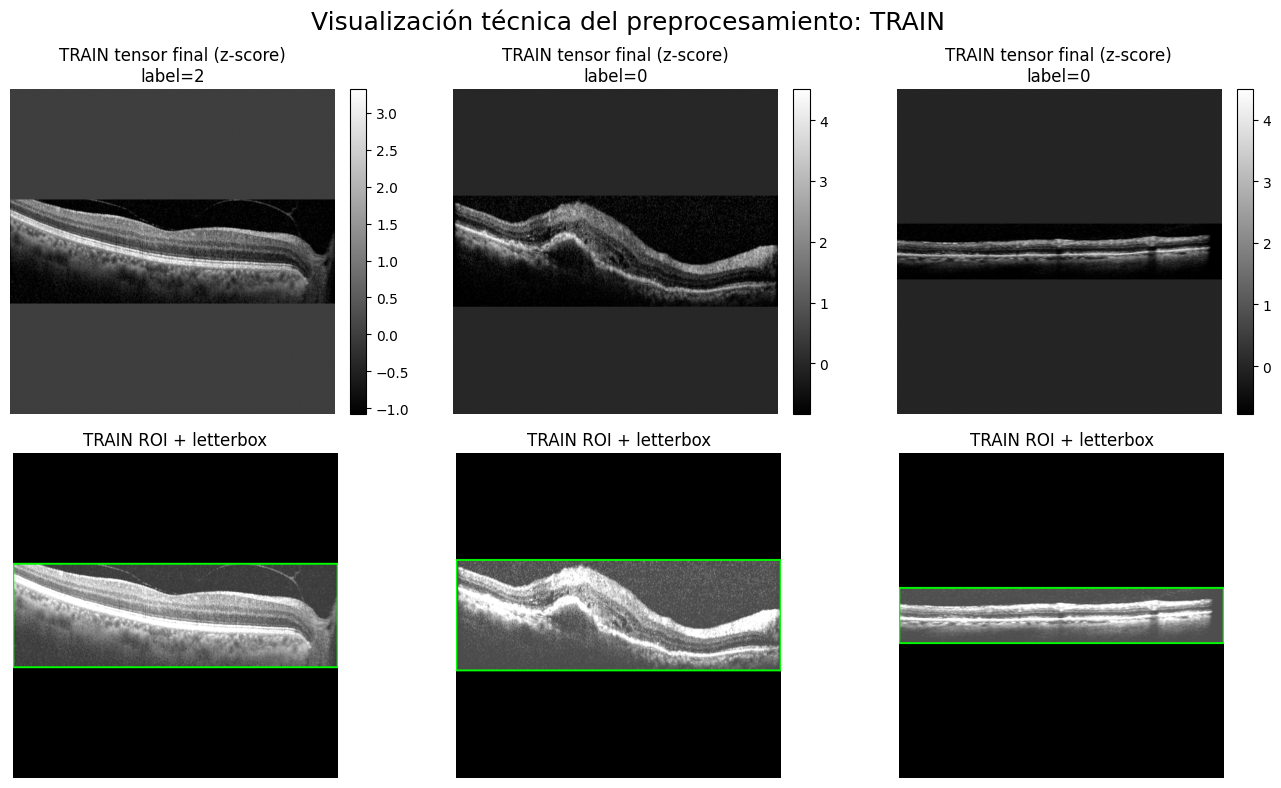

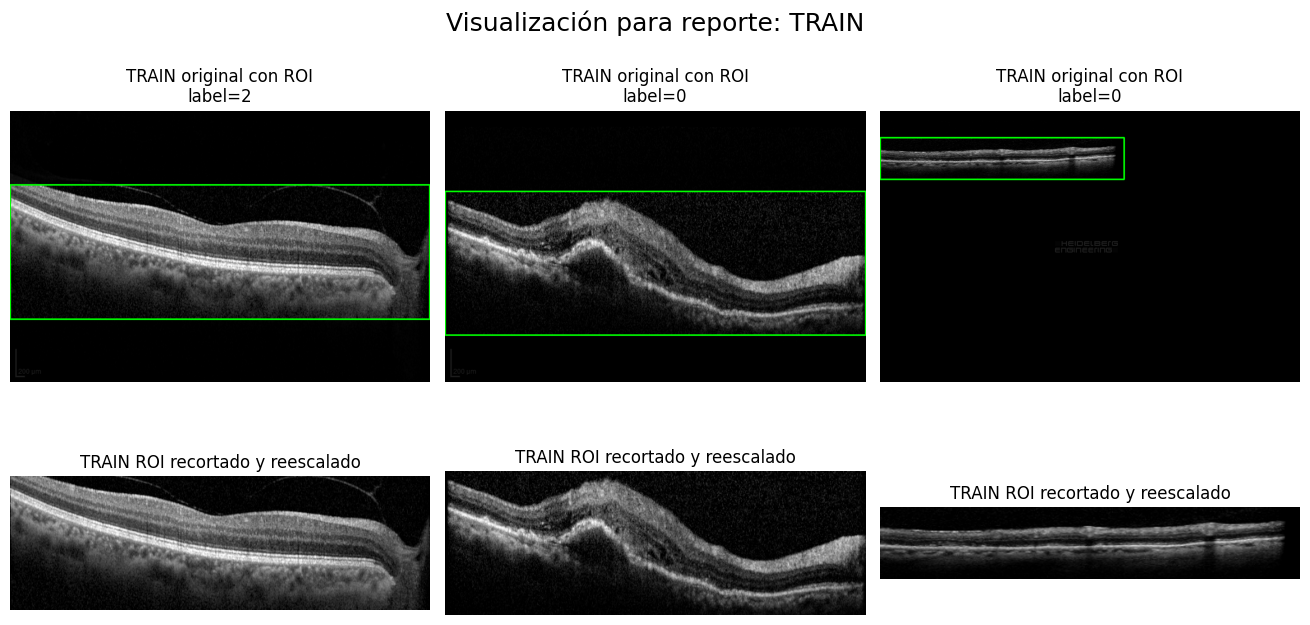

------------------------------------------------------------------------------------------
[VAL 1/3]
image_path   : NEH_UT_2021RetinalOCTDataset\DRUSEN/106/OS/023_Drusen.tif
label_id     : 1
orig_shape   : (496, 768)
roi_bbox     : (126, 314, 0, 768)
roi_shape    : (188, 768)
letterbox_hw : (125, 512)
valid_pixels : 64000
z_mean       : 0.327750
z_std        : 0.252102
------------------------------------------------------------------------------------------
[VAL 2/3]
image_path   : NEH_UT_2021RetinalOCTDataset\DRUSEN/85/018_Drusen.tif
label_id     : 1
orig_shape   : (496, 768)
roi_bbox     : (115, 283, 0, 768)
roi_shape    : (168, 768)
letterbox_hw : (112, 512)
valid_pixels : 57344
z_mean       : 0.265743
z_std        : 0.228243
------------------------------------------------------------------------------------------
[VAL 3/3]
image_path   : NEH_UT_2021RetinalOCTDataset\DRUSEN/85/024_Drusen.tif
label_id     : 1
orig_shape   : (496, 768)
roi_bbox     : (90, 287, 0, 768)
roi_shape    :

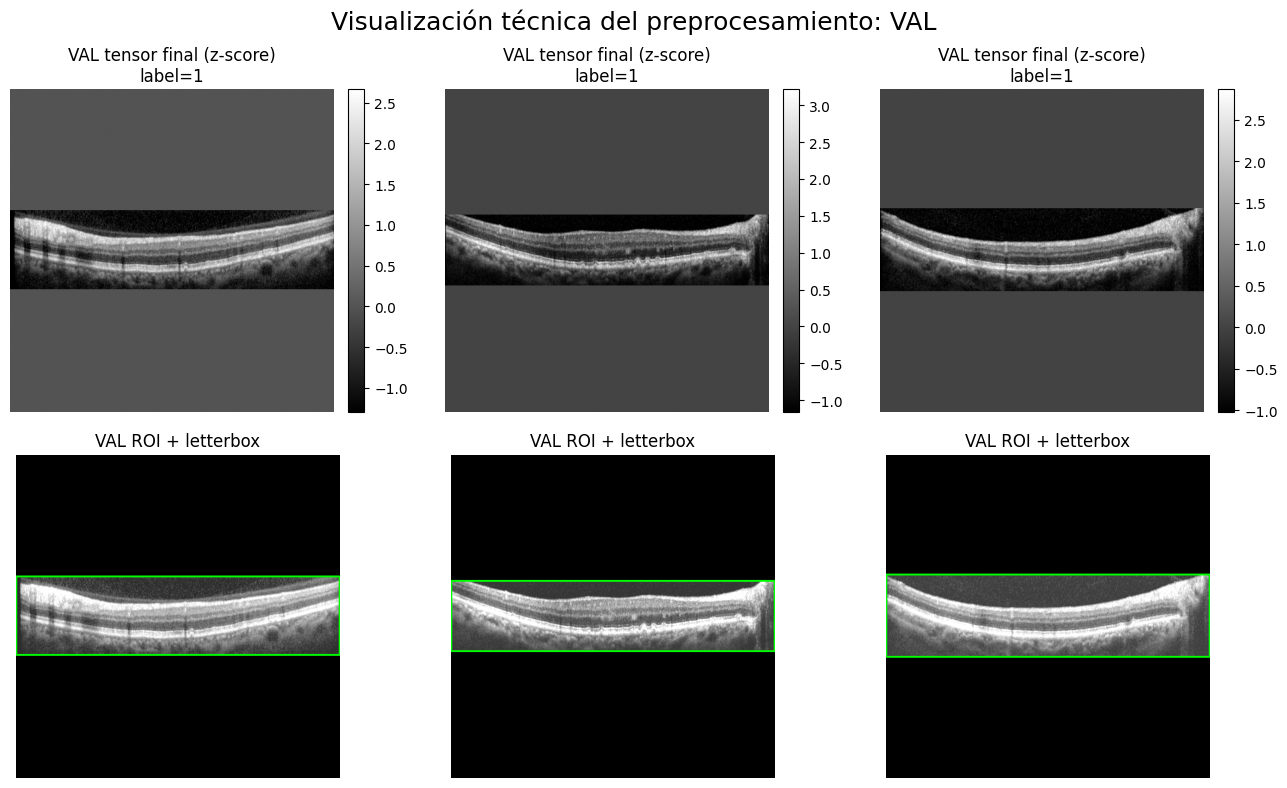

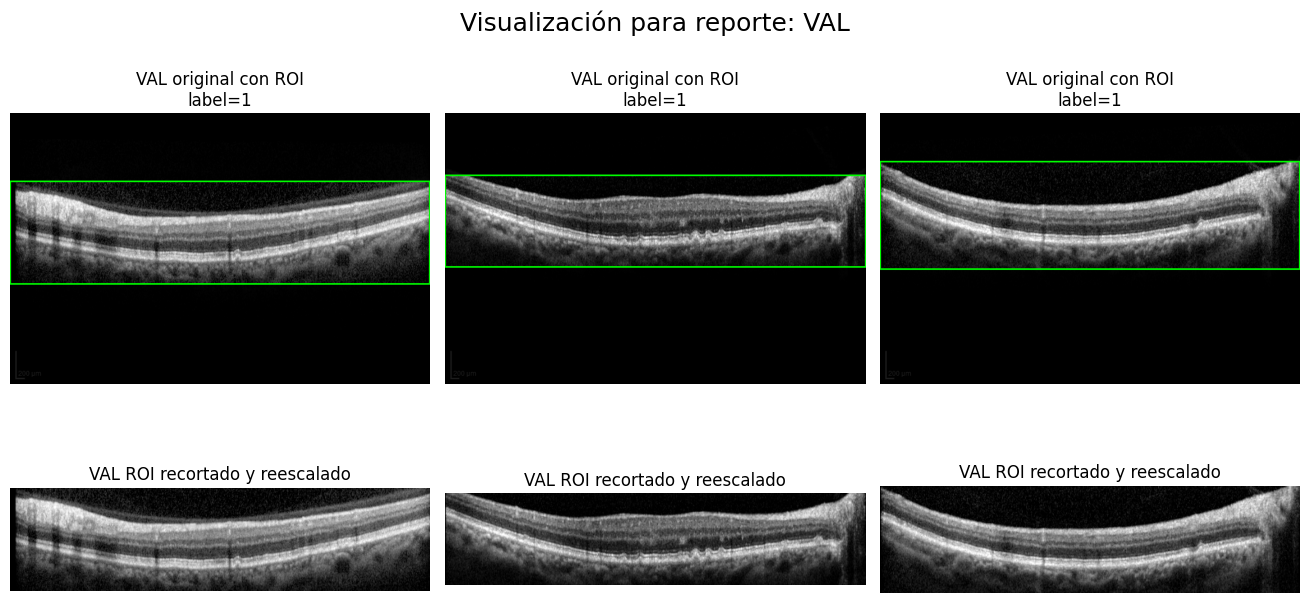

------------------------------------------------------------------------------------------
[TEST 1/3]
image_path   : NEH_UT_2021RetinalOCTDataset\CNV/150/020_CNV.tif
label_id     : 0
orig_shape   : (496, 768)
roi_bbox     : (200, 382, 0, 768)
roi_shape    : (182, 768)
letterbox_hw : (121, 512)
valid_pixels : 61952
z_mean       : 0.335344
z_std        : 0.243065
------------------------------------------------------------------------------------------
[TEST 2/3]
image_path   : NEH_UT_2021RetinalOCTDataset\DRUSEN/3/002_Drusen.jpg
label_id     : 1
orig_shape   : (496, 768)
roi_bbox     : (114, 325, 0, 767)
roi_shape    : (211, 767)
letterbox_hw : (141, 512)
valid_pixels : 72192
z_mean       : 0.179885
z_std        : 0.223309
------------------------------------------------------------------------------------------
[TEST 3/3]
image_path   : NEH_UT_2021RetinalOCTDataset\DRUSEN/59/009_Drusen.tif
label_id     : 1
orig_shape   : (496, 768)
roi_bbox     : (131, 316, 0, 768)
roi_shape    : (185,

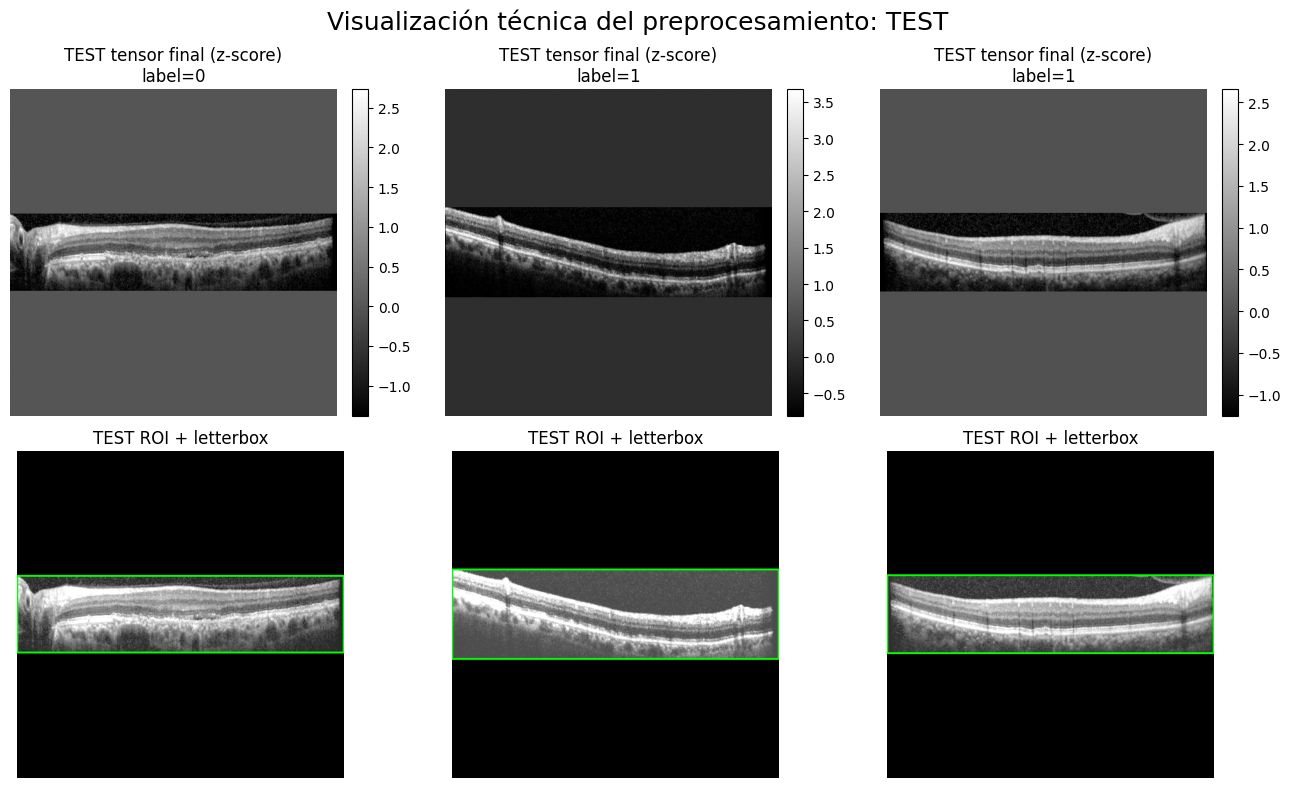

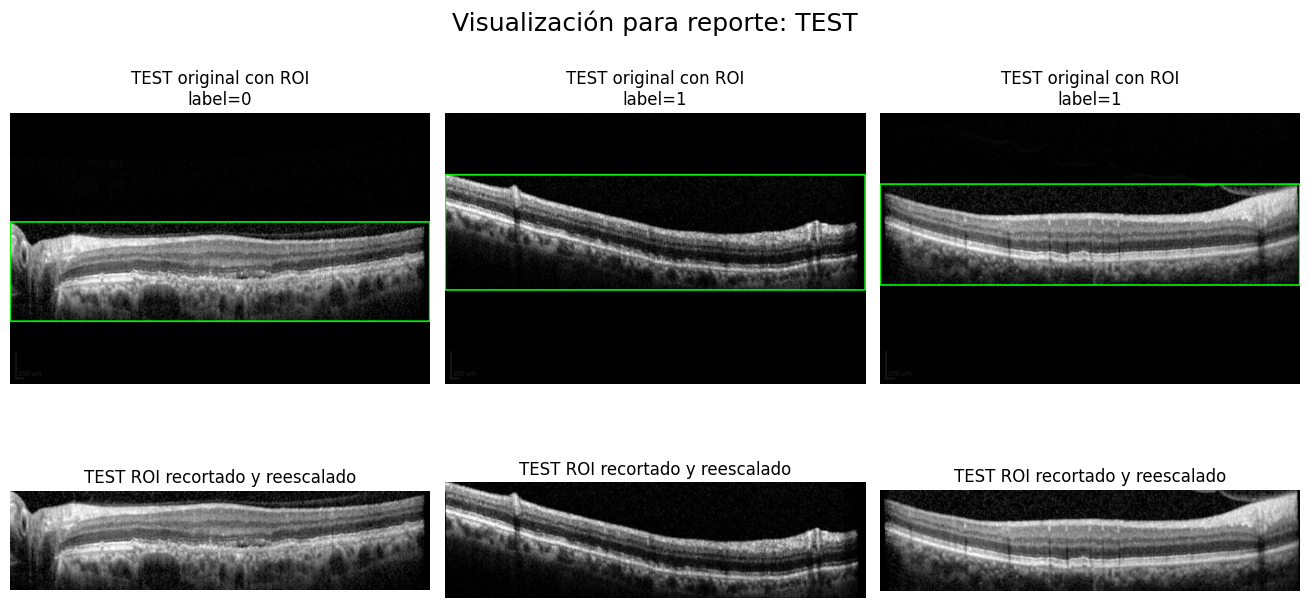

In [23]:
# ============================================================
# 🖼️ CELDA 5 — Visualización técnica + visualización para reporte
#               (TRAIN / VAL / TEST, muestreo aleatorio reproducible)
# ============================================================

NUM_SAMPLES_PER_SPLIT = 3
VIS_RANDOM_STATE = 42
VAL_FOLD_ID_FOR_VIS = 1

# ------------------------------------------------------------
# Cargar un VAL real desde un fold
# ------------------------------------------------------------
VAL_VIS_CSV = SPLITS_DIR / f"fold_{VAL_FOLD_ID_FOR_VIS}_val.csv"
assert VAL_VIS_CSV.exists(), f"No existe {VAL_VIS_CSV}"

df_val_vis_source = pd.read_csv(VAL_VIS_CSV)

assert len(df_train_outer) >= NUM_SAMPLES_PER_SPLIT, "No hay suficientes muestras en train_outer"
assert len(df_val_vis_source) >= NUM_SAMPLES_PER_SPLIT, "No hay suficientes muestras en val"
assert len(df_test_outer) >= NUM_SAMPLES_PER_SPLIT, "No hay suficientes muestras en test_outer"

# ------------------------------------------------------------
# Muestreo aleatorio reproducible
# ------------------------------------------------------------
df_train_vis = df_train_outer.sample(NUM_SAMPLES_PER_SPLIT, random_state=VIS_RANDOM_STATE).reset_index(drop=True)
df_val_vis   = df_val_vis_source.sample(NUM_SAMPLES_PER_SPLIT, random_state=VIS_RANDOM_STATE).reset_index(drop=True)
df_test_vis  = df_test_outer.sample(NUM_SAMPLES_PER_SPLIT, random_state=VIS_RANDOM_STATE).reset_index(drop=True)

# ------------------------------------------------------------
# Utilidades de preprocesamiento para visualización
# ------------------------------------------------------------
def preprocess_for_visualization(image_path, out_size=512, roi_margin=16, eps=1e-6):
    img = load_grayscale_image(image_path)                             # original [0,1]
    roi_img, bbox = roi_crop(img, margin=roi_margin, eps=eps)         # ROI [0,1]
    lb_img, valid_mask, lb_info = letterbox_square(roi_img, out_size=out_size)  # letterbox [0,1]
    z_img, mean, std = zscore_on_mask(lb_img, valid_mask, eps=eps)    # tensor final
    z_vis = denorm_for_display(z_img, valid_mask=valid_mask, vmin=-2.0, vmax=2.0)

    return {
        "img": img,
        "roi_img": roi_img,
        "bbox": bbox,
        "lb_img": lb_img,
        "valid_mask": valid_mask,
        "lb_info": lb_info,
        "z_img": z_img,
        "z_vis": z_vis,
        "mean": mean,
        "std": std,
    }


def draw_green_letterbox_frame(img_2d, valid_mask, thickness=2):
    """
    Dibuja el rectángulo verde de la región ocupada por el ROI dentro del letterbox.
    """
    vis = cv2.cvtColor((np.clip(img_2d, 0, 1) * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)

    ys, xs = np.where(valid_mask)
    if len(ys) > 0 and len(xs) > 0:
        y0, y1 = ys.min(), ys.max() + 1
        x0, x1 = xs.min(), xs.max() + 1
        cv2.rectangle(vis, (x0, y0), (x1 - 1, y1 - 1), (0, 255, 0), thickness)

    return vis


def draw_roi_highlight_on_original(img_2d, bbox, thickness=2, dim_outside=True, dim_alpha=0.12):
    """
    Resalta el ROI sobre la imagen original.
    Atenúa lo que queda fuera del ROI para que fondo/logos distraigan menos.
    """
    base = np.clip(img_2d, 0, 1).astype(np.float32)

    if dim_outside:
        vis = base * dim_alpha
        y0, y1, x0, x1 = bbox
        vis[y0:y1, x0:x1] = base[y0:y1, x0:x1]
    else:
        vis = base.copy()

    vis = cv2.cvtColor((vis * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
    y0, y1, x0, x1 = bbox
    cv2.rectangle(vis, (x0, y0), (x1 - 1, y1 - 1), (0, 255, 0), thickness)
    return vis


def crop_to_valid_region(img_2d, valid_mask, pad=0):
    """
    Recorta solo la región válida del letterbox para una visualización más limpia.
    Esto NO cambia el tensor real de entrenamiento; solo la figura.
    """
    ys, xs = np.where(valid_mask)
    if len(ys) == 0 or len(xs) == 0:
        return img_2d

    y0, y1 = ys.min(), ys.max() + 1
    x0, x1 = xs.min(), xs.max() + 1

    y0 = max(0, y0 - pad)
    y1 = min(img_2d.shape[0], y1 + pad)
    x0 = max(0, x0 - pad)
    x1 = min(img_2d.shape[1], x1 + pad)

    return img_2d[y0:y1, x0:x1]


# ------------------------------------------------------------
# Figura 1: visualización técnica
# ------------------------------------------------------------
def visualize_split_technical(df_samples, split_name, out_size=512, roi_margin=16):
    n = len(df_samples)
    fig, axes = plt.subplots(2, n, figsize=(4.4 * n, 8))

    if n == 1:
        axes = np.array(axes).reshape(2, 1)

    fig.suptitle(f"Visualización técnica del preprocesamiento: {split_name}", fontsize=18, y=0.98)

    for j, row in df_samples.iterrows():
        image_path = row["image_path"]
        label_id = row["label_id"] if "label_id" in row else "N/A"

        pack = preprocess_for_visualization(
            image_path=image_path,
            out_size=out_size,
            roi_margin=roi_margin,
            eps=EPS
        )

        # Arriba: tensor final real (z-score)
        im0 = axes[0, j].imshow(pack["z_img"], cmap="gray")
        axes[0, j].set_title(f"{split_name} tensor final (z-score)\nlabel={label_id}", fontsize=12)
        axes[0, j].axis("off")
        plt.colorbar(im0, ax=axes[0, j], fraction=0.046, pad=0.04)

        # Abajo: ROI + letterbox, ventana amigable para inspección
        lb_green = draw_green_letterbox_frame(pack["z_vis"], pack["valid_mask"], thickness=2)
        axes[1, j].imshow(lb_green)
        axes[1, j].set_title(f"{split_name} ROI + letterbox", fontsize=12)
        axes[1, j].axis("off")

        print("-" * 90)
        print(f"[{split_name} {j+1}/{n}]")
        print(f"image_path   : {image_path}")
        print(f"label_id     : {label_id}")
        print(f"orig_shape   : {pack['img'].shape}")
        print(f"roi_bbox     : {pack['bbox']}")
        print(f"roi_shape    : {pack['roi_img'].shape}")
        print(f"letterbox_hw : ({pack['lb_info']['new_h']}, {pack['lb_info']['new_w']})")
        print(f"valid_pixels : {int(pack['valid_mask'].sum())}")
        print(f"z_mean       : {pack['mean']:.6f}")
        print(f"z_std        : {pack['std']:.6f}")

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Figura 2: visualización para reporte / tesis
# ------------------------------------------------------------
def visualize_split_for_report(df_samples, split_name, out_size=512, roi_margin=16, crop_valid=True):
    n = len(df_samples)
    fig, axes = plt.subplots(2, n, figsize=(4.4 * n, 7.5))

    if n == 1:
        axes = np.array(axes).reshape(2, 1)

    fig.suptitle(f"Visualización para reporte: {split_name}", fontsize=18, y=0.98)

    for j, row in df_samples.iterrows():
        image_path = row["image_path"]
        label_id = row["label_id"] if "label_id" in row else "N/A"

        pack = preprocess_for_visualization(
            image_path=image_path,
            out_size=out_size,
            roi_margin=roi_margin,
            eps=EPS
        )

        # Arriba: original con ROI resaltado y exterior atenuado
        orig_highlight = draw_roi_highlight_on_original(
            pack["img"],
            pack["bbox"],
            thickness=2,
            dim_outside=True,
            dim_alpha=0.12
        )
        axes[0, j].imshow(orig_highlight)
        axes[0, j].set_title(f"{split_name} original con ROI\nlabel={label_id}", fontsize=12)
        axes[0, j].axis("off")

        # Abajo: ROI recortado y reescalado sobre intensidad natural [0,1]
        thesis_img = pack["lb_img"]
        if crop_valid:
            thesis_img = crop_to_valid_region(pack["lb_img"], pack["valid_mask"], pad=0)

        axes[1, j].imshow(thesis_img, cmap="gray", vmin=0.0, vmax=1.0)
        axes[1, j].set_title(f"{split_name} ROI recortado y reescalado", fontsize=12)
        axes[1, j].axis("off")

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Ejecutar visualizaciones para TRAIN / VAL / TEST
# ------------------------------------------------------------
for split_name, df_split in [
    ("TRAIN", df_train_vis),
    ("VAL",   df_val_vis),
    ("TEST",  df_test_vis),
]:
    visualize_split_technical(
        df_split,
        split_name=split_name,
        out_size=IMG_SIZE,
        roi_margin=ROI_MARGIN
    )

    visualize_split_for_report(
        df_split,
        split_name=split_name,
        out_size=IMG_SIZE,
        roi_margin=ROI_MARGIN,
        crop_valid=True
    )

Dataset base preprocesado

In [24]:
class OCTDatasetBasePreprocessed(Dataset):
    """
    Dataset base para materialización offline en CPU.

    Recibe un DataFrame con al menos:
      - image_path
      - label_id

    Para cada muestra:
      1) carga la imagen
      2) aplica preprocess_image_fixed
      3) devuelve tensor preprocesado + etiqueta + metadatos
    """

    def __init__(
        self,
        df,
        out_size=512,
        roi_margin=16,
        eps=1e-6,
        return_meta=True
    ):
        self.df = df.reset_index(drop=True).copy()
        self.out_size = out_size
        self.roi_margin = roi_margin
        self.eps = eps
        self.return_meta = return_meta

        required_cols = ["image_path", "label_id"]
        for col in required_cols:
            if col not in self.df.columns:
                raise ValueError(f"Falta columna requerida: '{col}'")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = row["image_path"]
        label_id = int(row["label_id"])

        x, prep_meta = preprocess_image_fixed(
            image_path=image_path,
            out_size=self.out_size,
            roi_margin=self.roi_margin,
            eps=self.eps
        )

        y = np.int64(label_id)

        # Metadatos base de la fila
        meta = {
            "dataset_idx": int(idx),
            "image_path": str(image_path),
            "label_id": int(label_id),
        }

        # Agregar columnas útiles si existen
        optional_cols = [
            "label",
            "patient_id",
            "patient_class",
            "group_id",
            "eye",
            "bscan",
            "directory",
        ]

        for col in optional_cols:
            if col in row.index:
                value = row[col]
                if pd.isna(value):
                    value = None
                meta[col] = value

        # Agregar metadatos del preprocesamiento
        meta.update(prep_meta)

        if self.return_meta:
            return x, y, meta
        else:
            return x, y


print("=" * 90)
print("✅ Dataset OCTDatasetBasePreprocessed definido")
print("=" * 90)
print("Salida por muestra:")
print("- x : np.ndarray [1, IMG_SIZE, IMG_SIZE], float32")
print("- y : np.int64")
print("- meta : dict")

✅ Dataset OCTDatasetBasePreprocessed definido
Salida por muestra:
- x : np.ndarray [1, IMG_SIZE, IMG_SIZE], float32
- y : np.int64
- meta : dict


Sanity check del dataset base

📦 DATASETS BASE CREADOS
Train base dataset: 10,128 muestras
Test  base dataset: 2,521 muestras

🔎 INSPECCIÓN DE MUESTRA — TRAIN_BASE[0]
x.shape        : (1, 512, 512)
x.dtype        : float32
x.min / x.max  : -1.0126 / 3.0186
label (y)      : 0
image_path     : NEH_UT_2021RetinalOCTDataset\CNV/1/011_CNV.jpg
orig_shape     : (496, 768)
roi_bbox       : (25, 317, 0, 768)
roi_shape      : (292, 768)
valid_pixels   : 99840
zscore_mean    : 0.251184
zscore_std     : 0.248060
group_id      : CNV_1
patient_id    : 1
patient_class : CNV
label         : CNV
eye           : OS
bscan         : 11

🔎 INSPECCIÓN DE MUESTRA — TEST_BASE[0]
x.shape        : (1, 512, 512)
x.dtype        : float32
x.min / x.max  : -0.9795 / 3.6877
label (y)      : 0
image_path     : NEH_UT_2021RetinalOCTDataset\CNV/10/OD/020_CNV.tif
orig_shape     : (496, 768)
roi_bbox       : (152, 323, 0, 768)
roi_shape      : (171, 768)
valid_pixels   : 58368
zscore_mean    : 0.209301
zscore_std     : 0.213685
group_id      : CNV_10


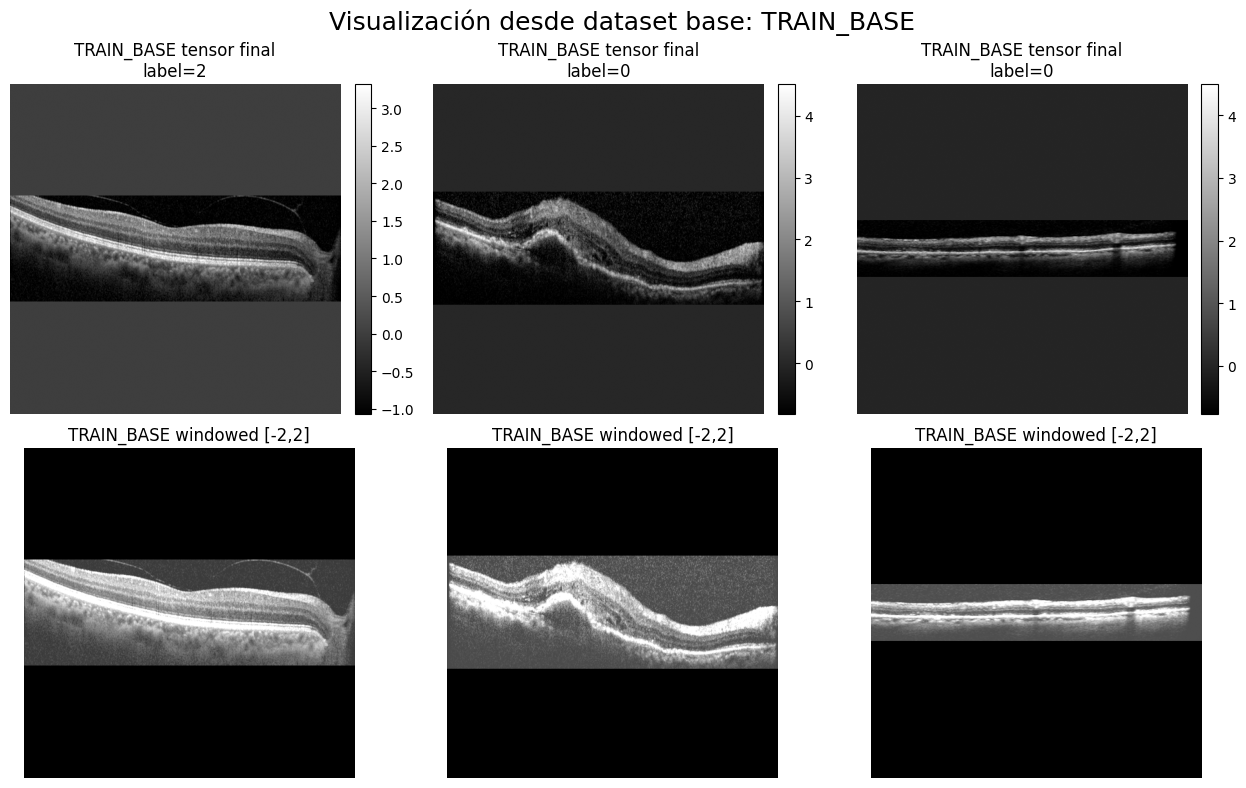

------------------------------------------------------------------------------------------
[TEST_BASE sample 1/3] idx=2039
image_path   : NEH_UT_2021RetinalOCTDataset\NORMAL/45/002_Normal.tif
label_id     : 2
roi_bbox     : (55, 289, 0, 768)
roi_shape    : (234, 768)
valid_pixels : 79872
------------------------------------------------------------------------------------------
[TEST_BASE sample 2/3] idx=365
image_path   : NEH_UT_2021RetinalOCTDataset\CNV/37/029_CNV.tif
label_id     : 0
roi_bbox     : (197, 366, 0, 768)
roi_shape    : (169, 768)
valid_pixels : 57856
------------------------------------------------------------------------------------------
[TEST_BASE sample 3/3] idx=1081
image_path   : NEH_UT_2021RetinalOCTDataset\DRUSEN/56/015_Drusen.tif
label_id     : 1
roi_bbox     : (125, 301, 0, 768)
roi_shape    : (176, 768)
valid_pixels : 59904


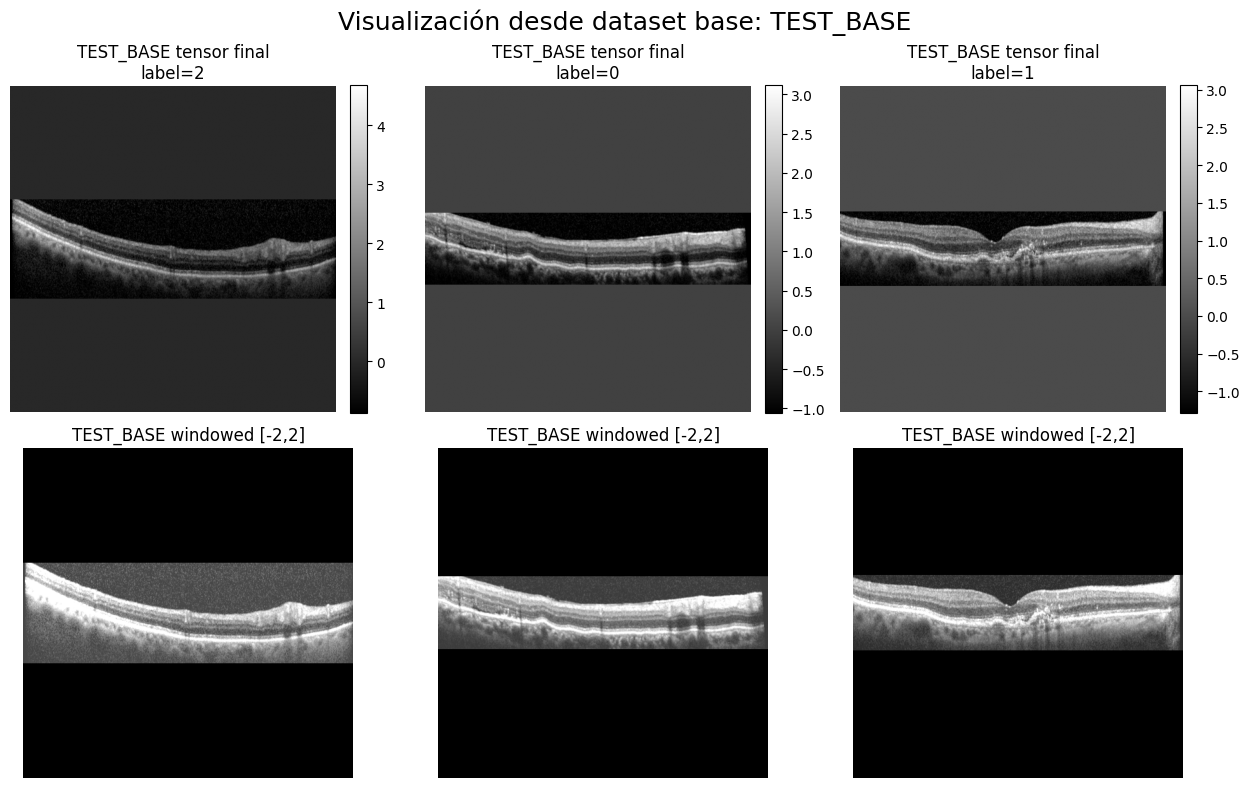

In [25]:
# ------------------------------------------------------------
# Instanciar datasets base
# ------------------------------------------------------------
train_base_ds = OCTDatasetBasePreprocessed(
    df=df_train_outer,
    out_size=IMG_SIZE,
    roi_margin=ROI_MARGIN,
    eps=EPS,
    return_meta=True
)

test_base_ds = OCTDatasetBasePreprocessed(
    df=df_test_outer,
    out_size=IMG_SIZE,
    roi_margin=ROI_MARGIN,
    eps=EPS,
    return_meta=True
)

print("=" * 90)
print("📦 DATASETS BASE CREADOS")
print("=" * 90)
print(f"Train base dataset: {len(train_base_ds):,} muestras")
print(f"Test  base dataset: {len(test_base_ds):,} muestras")


# ------------------------------------------------------------
# Función para inspeccionar una muestra
# ------------------------------------------------------------
def inspect_dataset_sample(ds, idx, split_name="DATASET"):
    x, y, meta = ds[idx]

    print("\n" + "=" * 90)
    print(f"🔎 INSPECCIÓN DE MUESTRA — {split_name}[{idx}]")
    print("=" * 90)
    print(f"x.shape        : {x.shape}")
    print(f"x.dtype        : {x.dtype}")
    print(f"x.min / x.max  : {x.min():.4f} / {x.max():.4f}")
    print(f"label (y)      : {y}")
    print(f"image_path     : {meta.get('image_path', None)}")
    print(f"orig_shape     : {meta.get('orig_shape', None)}")
    print(f"roi_bbox       : {meta.get('roi_bbox', None)}")
    print(f"roi_shape      : {meta.get('roi_shape', None)}")
    print(f"valid_pixels   : {meta.get('valid_pixels', None)}")
    print(f"zscore_mean    : {meta.get('zscore_mean', None):.6f}")
    print(f"zscore_std     : {meta.get('zscore_std', None):.6f}")

    # Mostrar metadatos opcionales si existen
    optional_keys = ["group_id", "patient_id", "patient_class", "label", "eye", "bscan"]
    for k in optional_keys:
        if k in meta:
            print(f"{k:14}: {meta[k]}")

    return x, y, meta


# ------------------------------------------------------------
# Inspección puntual de muestras
# ------------------------------------------------------------
_ = inspect_dataset_sample(train_base_ds, idx=0, split_name="TRAIN_BASE")
_ = inspect_dataset_sample(test_base_ds, idx=0, split_name="TEST_BASE")


# ------------------------------------------------------------
# Visualización de ejemplos desde el dataset ya empaquetado
# ------------------------------------------------------------
def visualize_dataset_samples(ds, split_name="DATASET", n_samples=3, random_samples=True):
    assert len(ds) >= n_samples, f"{split_name} no tiene suficientes muestras"

    if random_samples:
        indices = np.random.choice(len(ds), size=n_samples, replace=False)
    else:
        indices = np.arange(n_samples)

    fig, axes = plt.subplots(2, n_samples, figsize=(4.2 * n_samples, 8))

    if n_samples == 1:
        axes = np.array(axes).reshape(2, 1)

    fig.suptitle(f"Visualización desde dataset base: {split_name}", fontsize=18, y=0.98)

    for j, idx in enumerate(indices):
        x, y, meta = ds[idx]

        # x: [1, H, W] z-score real
        z_img = x[0]

        # reconstrucción amigable para visualizar
        valid_mask = np.zeros_like(z_img, dtype=bool)
        lb_info = meta["letterbox_info"]
        top = lb_info["top"]
        left = lb_info["left"]
        new_h = lb_info["new_h"]
        new_w = lb_info["new_w"]
        valid_mask[top:top + new_h, left:left + new_w] = True

        z_vis = denorm_for_display(z_img, valid_mask=valid_mask, vmin=-2.0, vmax=2.0)

        # arriba: tensor real
        im0 = axes[0, j].imshow(z_img, cmap="gray")
        axes[0, j].set_title(f"{split_name} tensor final\nlabel={y}", fontsize=12)
        axes[0, j].axis("off")
        plt.colorbar(im0, ax=axes[0, j], fraction=0.046, pad=0.04)

        # abajo: versión amigable
        axes[1, j].imshow(z_vis, cmap="gray", vmin=0.0, vmax=1.0)
        axes[1, j].set_title(f"{split_name} windowed [-2,2]", fontsize=12)
        axes[1, j].axis("off")

        print("-" * 90)
        print(f"[{split_name} sample {j+1}/{n_samples}] idx={idx}")
        print(f"image_path   : {meta['image_path']}")
        print(f"label_id     : {y}")
        print(f"roi_bbox     : {meta['roi_bbox']}")
        print(f"roi_shape    : {meta['roi_shape']}")
        print(f"valid_pixels : {meta['valid_pixels']}")

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Ejecutar visualización del dataset base
# ------------------------------------------------------------
visualize_dataset_samples(train_base_ds, split_name="TRAIN_BASE", n_samples=3, random_samples=True)
visualize_dataset_samples(test_base_ds,  split_name="TEST_BASE",  n_samples=3, random_samples=True)

Materialización del dataset base

In [26]:

def materialize_base_dataset(
    dataset,
    df_source,
    split_name,
    out_dir,
    shard_size=512
):
    """
    Materializa un dataset base preprocesado en shards .npy y genera
    un índice maestro CSV con correspondencia 1:1 entre filas del DataFrame
    original y posiciones dentro de los shards.
    """
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    n = len(dataset)
    assert n == len(df_source), "dataset y df_source deben tener la misma longitud"

    print("=" * 90)
    print(f"🚀 MATERIALIZANDO DATASET BASE: {split_name}")
    print("=" * 90)
    print(f"Muestras totales : {n:,}")
    print(f"Shard size       : {shard_size}")
    print(f"Output dir       : {out_dir}")

    shard_records = []
    index_records = []

    n_shards = math.ceil(n / shard_size)

    # ------------------------------------------------------------
    # Barra total
    # ------------------------------------------------------------
    pbar_total = tqdm(total=n, desc=f"{split_name} total", unit="img")

    for shard_id in range(n_shards):
        start = shard_id * shard_size
        end = min(start + shard_size, n)

        X_list = []
        y_list = []

        print(f"\n[{split_name}] shard {shard_id+1}/{n_shards} | muestras {start}:{end}")

        # --------------------------------------------------------
        # Barra por shard
        # --------------------------------------------------------
        for idx in tqdm(
            range(start, end),
            desc=f"{split_name} shard {shard_id:03d}",
            unit="img",
            leave=False
        ):
            x, y, meta = dataset[idx]

            X_list.append(x.astype(np.float32))
            y_list.append(np.int64(y))

            row = df_source.iloc[idx].to_dict()

            index_row = {
                "base_idx": int(idx),
                "split_name": split_name,
                "shard_id": int(shard_id),
                "shard_pos": int(idx - start),
                "label_id": int(y),
                "image_path": str(meta["image_path"]),
            }

            # columnas originales del dataframe
            for k, v in row.items():
                if k not in index_row:
                    if pd.isna(v):
                        v = None
                    index_row[k] = v

            # metadatos útiles del preprocesamiento
            index_row["orig_shape"] = str(meta.get("orig_shape", None))
            index_row["roi_bbox"] = str(meta.get("roi_bbox", None))
            index_row["roi_shape"] = str(meta.get("roi_shape", None))
            index_row["valid_pixels"] = int(meta.get("valid_pixels", 0))
            index_row["zscore_mean"] = float(meta.get("zscore_mean", 0.0))
            index_row["zscore_std"] = float(meta.get("zscore_std", 1.0))

            index_records.append(index_row)
            pbar_total.update(1)

        X_shard = np.stack(X_list, axis=0).astype(np.float32)   # [N, 1, 512, 512]
        y_shard = np.array(y_list, dtype=np.int64)              # [N]

        x_path = out_dir / f"{split_name}_X_{shard_id:03d}.npy"
        y_path = out_dir / f"{split_name}_y_{shard_id:03d}.npy"

        np.save(x_path, X_shard)
        np.save(y_path, y_shard)

        shard_info = {
            "shard_id": int(shard_id),
            "start_idx": int(start),
            "end_idx": int(end),
            "num_samples": int(end - start),
            "x_path": str(x_path),
            "y_path": str(y_path),
            "x_shape": tuple(int(v) for v in X_shard.shape),
            "y_shape": tuple(int(v) for v in y_shard.shape),
        }
        shard_records.append(shard_info)

        print(f"  ✅ Guardado X: {x_path.name}  shape={X_shard.shape}")
        print(f"  ✅ Guardado y: {y_path.name}  shape={y_shard.shape}")

        del X_list, y_list, X_shard, y_shard
        gc.collect()

    pbar_total.close()

    # ------------------------------------------------------------
    # Guardar índice maestro
    # ------------------------------------------------------------
    df_index = pd.DataFrame(index_records)
    index_csv_path = out_dir / f"{split_name}_base_index.csv"
    df_index.to_csv(index_csv_path, index=False)

    # ------------------------------------------------------------
    # Guardar metadatos globales
    # ------------------------------------------------------------
    meta = {
        "split_name": split_name,
        "num_samples": int(n),
        "shard_size": int(shard_size),
        "num_shards": int(n_shards),
        "image_shape": [1, IMG_SIZE, IMG_SIZE],
        "dtype_x": "float32",
        "dtype_y": "int64",
        "index_csv": str(index_csv_path),
        "shards": shard_records,
    }

    meta_json_path = out_dir / f"{split_name}_meta.json"
    with open(meta_json_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2, ensure_ascii=False)

    print("\n" + "=" * 90)
    print(f"✅ MATERIALIZACIÓN COMPLETADA: {split_name}")
    print("=" * 90)
    print(f"Index CSV     : {index_csv_path}")
    print(f"Meta JSON     : {meta_json_path}")
    print(f"Número shards : {n_shards}")

    return df_index, meta


# ------------------------------------------------------------
# Materializar TRAIN_OUTER base
# ------------------------------------------------------------
df_train_base_index, train_base_meta = materialize_base_dataset(
    dataset=train_base_ds,
    df_source=df_train_outer,
    split_name="train_outer",
    out_dir=TRAIN_BASE_DIR,
    shard_size=SHARD_SIZE
)

# ------------------------------------------------------------
# Materializar TEST_OUTER base
# ------------------------------------------------------------
df_test_base_index, test_base_meta = materialize_base_dataset(
    dataset=test_base_ds,
    df_source=df_test_outer,
    split_name="test_outer",
    out_dir=TEST_BASE_DIR,
    shard_size=SHARD_SIZE
)

🚀 MATERIALIZANDO DATASET BASE: train_outer
Muestras totales : 10,128
Shard size       : 512
Output dir       : C:\Users\olide\Documents\Maestría\Dataset\OCT_base_cv5\train_outer


train_outer total:   0%|          | 0/10128 [00:00<?, ?img/s]


[train_outer] shard 1/20 | muestras 0:512


train_outer total:   5%|▌         | 512/10128 [00:10<03:28, 46.22img/s]

  ✅ Guardado X: train_outer_X_000.npy  shape=(512, 1, 512, 512)
  ✅ Guardado y: train_outer_y_000.npy  shape=(512,)

[train_outer] shard 2/20 | muestras 512:1024


...

  ✅ Guardado X: test_outer_X_003.npy  shape=(512, 1, 512, 512)
  ✅ Guardado y: test_outer_y_003.npy  shape=(512,)

[test_outer] shard 5/5 | muestras 2048:2521


test_outer total: 100%|██████████| 2521/2521 [01:00<00:00, 38.00img/s]

  ✅ Guardado X: test_outer_X_004.npy  shape=(473, 1, 512, 512)
  ✅ Guardado y: test_outer_y_004.npy  shape=(473,)


test_outer total: 100%|██████████| 2521/2521 [01:01<00:00, 41.20img/s]


✅ MATERIALIZACIÓN COMPLETADA: test_outer
Index CSV     : C:\Users\olide\Documents\Maestría\Dataset\OCT_base_cv5\test_outer\test_outer_base_index.csv
Meta JSON     : C:\Users\olide\Documents\Maestría\Dataset\OCT_base_cv5\test_outer\test_outer_meta.json
Número shards : 5


Validación de la materialización del dataset base

🔎 VALIDANDO MATERIALIZACIÓN: train_outer
Directorio : C:\Users\olide\Documents\Maestría\Dataset\OCT_base_cv5\train_outer
Esperado   : 10,128 muestras
Meta JSON   : train_outer_meta.json
Index CSV   : train_outer_base_index.csv
Filas index : 10,128
Número de shards detectados: 20
------------------------------------------------------------------------------------------
Shard 000
X file     : train_outer_X_000.npy
y file     : train_outer_y_000.npy
X shape    : (512, 1, 512, 512)
y shape    : (512,)
X dtype    : float32
y dtype    : int64
------------------------------------------------------------------------------------------
Shard 001
X file     : train_outer_X_001.npy
y file     : train_outer_y_001.npy
X shape    : (512, 1, 512, 512)
y shape    : (512,)
X dtype    : float32
y dtype    : int64
------------------------------------------------------------------------------------------
Shard 002
X file     : train_outer_X_002.npy
y file     : train_outer_y_002.npy
X shape    : (512, 1, 5

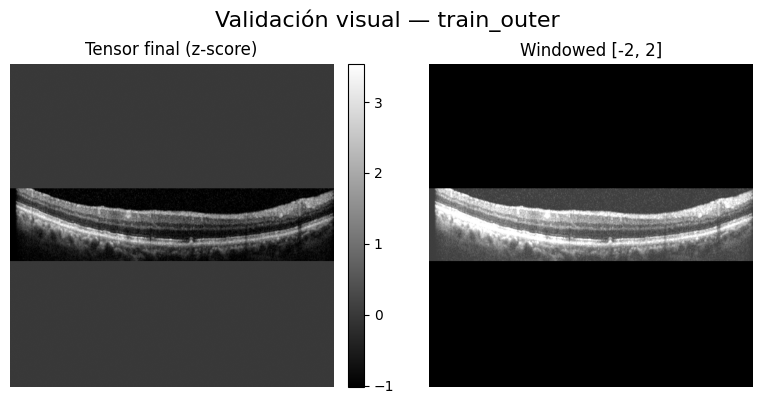


✅ Validación completada correctamente.
🔎 VALIDANDO MATERIALIZACIÓN: test_outer
Directorio : C:\Users\olide\Documents\Maestría\Dataset\OCT_base_cv5\test_outer
Esperado   : 2,521 muestras
Meta JSON   : test_outer_meta.json
Index CSV   : test_outer_base_index.csv
Filas index : 2,521
Número de shards detectados: 5
------------------------------------------------------------------------------------------
Shard 000
X file     : test_outer_X_000.npy
y file     : test_outer_y_000.npy
X shape    : (512, 1, 512, 512)
y shape    : (512,)
X dtype    : float32
y dtype    : int64
------------------------------------------------------------------------------------------
Shard 001
X file     : test_outer_X_001.npy
y file     : test_outer_y_001.npy
X shape    : (512, 1, 512, 512)
y shape    : (512,)
X dtype    : float32
y dtype    : int64
------------------------------------------------------------------------------------------
Shard 002
X file     : test_outer_X_002.npy
y file     : test_outer_y_002.

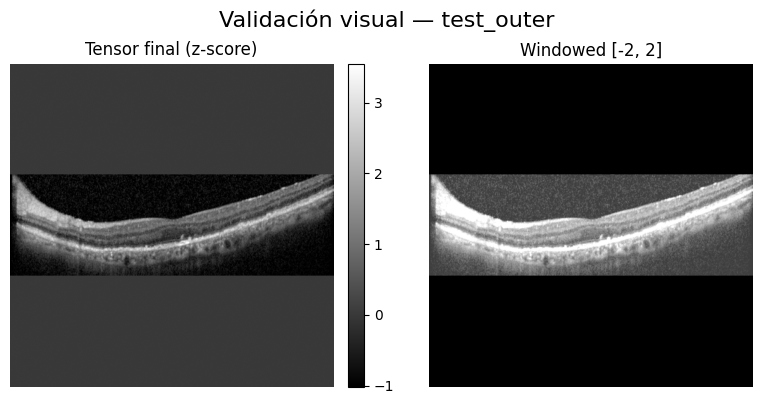


✅ Validación completada correctamente.


In [27]:

def validate_materialized_base(split_name, split_dir, expected_len):
    split_dir = Path(split_dir)

    print("=" * 90)
    print(f"🔎 VALIDANDO MATERIALIZACIÓN: {split_name}")
    print("=" * 90)
    print(f"Directorio : {split_dir}")
    print(f"Esperado   : {expected_len:,} muestras")

    # ------------------------------------------------------------
    # Rutas esperadas
    # ------------------------------------------------------------
    meta_json_path = split_dir / f"{split_name}_meta.json"
    index_csv_path = split_dir / f"{split_name}_base_index.csv"

    assert meta_json_path.exists(), f"No existe: {meta_json_path}"
    assert index_csv_path.exists(), f"No existe: {index_csv_path}"

    # ------------------------------------------------------------
    # Cargar metadata e índice maestro
    # ------------------------------------------------------------
    with open(meta_json_path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    df_index = pd.read_csv(index_csv_path)

    print(f"Meta JSON   : {meta_json_path.name}")
    print(f"Index CSV   : {index_csv_path.name}")
    print(f"Filas index : {len(df_index):,}")

    # ------------------------------------------------------------
    # Validaciones globales
    # ------------------------------------------------------------
    assert meta["split_name"] == split_name, "split_name inconsistente en meta.json"
    assert int(meta["num_samples"]) == expected_len, "num_samples inconsistente en meta.json"
    assert len(df_index) == expected_len, "base_index.csv no coincide con expected_len"

    # base_idx debe ser 0..N-1
    expected_base_idx = np.arange(expected_len)
    assert np.array_equal(df_index["base_idx"].values, expected_base_idx), \
        "base_idx no es consecutivo de 0 a N-1"

    # ------------------------------------------------------------
    # Detectar shards
    # ------------------------------------------------------------
    x_files = sorted(split_dir.glob(f"{split_name}_X_*.npy"))
    y_files = sorted(split_dir.glob(f"{split_name}_y_*.npy"))

    assert len(x_files) > 0, f"No se encontraron shards X para {split_name}"
    assert len(y_files) > 0, f"No se encontraron shards y para {split_name}"
    assert len(x_files) == len(y_files), "Número desigual de shards X/y"

    print(f"Número de shards detectados: {len(x_files)}")

    # ------------------------------------------------------------
    # Validar shard por shard
    # ------------------------------------------------------------
    total_count = 0

    for shard_id, (x_path, y_path) in enumerate(zip(x_files, y_files)):
        X = np.load(x_path, mmap_mode="r")
        y = np.load(y_path, mmap_mode="r")

        print("-" * 90)
        print(f"Shard {shard_id:03d}")
        print(f"X file     : {x_path.name}")
        print(f"y file     : {y_path.name}")
        print(f"X shape    : {X.shape}")
        print(f"y shape    : {y.shape}")
        print(f"X dtype    : {X.dtype}")
        print(f"y dtype    : {y.dtype}")

        assert X.ndim == 4, f"{x_path.name} debe tener shape [N, 1, H, W]"
        assert y.ndim == 1, f"{y_path.name} debe tener shape [N]"
        assert X.shape[0] == y.shape[0], f"Desajuste entre X e y en shard {shard_id}"
        assert X.shape[1] == 1, f"Canal inválido en {x_path.name}"
        assert X.shape[2] == IMG_SIZE and X.shape[3] == IMG_SIZE, \
            f"Tamaño espacial inválido en {x_path.name}"
        assert X.dtype == np.float32, f"dtype inválido en {x_path.name}"
        assert y.dtype == np.int64, f"dtype inválido en {y_path.name}"

        # Validar contra base_index.csv
        df_shard = df_index[df_index["shard_id"] == shard_id].copy()
        assert len(df_shard) == X.shape[0], \
            f"El index CSV no coincide con el tamaño del shard {shard_id}"

        # shard_pos debe ir de 0..len-1
        assert np.array_equal(df_shard["shard_pos"].values, np.arange(len(df_shard))), \
            f"shard_pos inconsistente en shard {shard_id}"

        total_count += X.shape[0]

    print("-" * 90)
    print(f"Total reconstruido desde shards: {total_count:,}")
    assert total_count == expected_len, "La suma de muestras de shards no coincide con expected_len"

    # ------------------------------------------------------------
    # Inspección puntual de una muestra
    # ------------------------------------------------------------
    print("\n" + "=" * 90)
    print("🔬 INSPECCIÓN PUNTUAL DE UNA MUESTRA")
    print("=" * 90)

    sample_row = df_index.iloc[len(df_index) // 2]  # muestra intermedia
    sample_shard_id = int(sample_row["shard_id"])
    sample_shard_pos = int(sample_row["shard_pos"])

    X_sample = np.load(split_dir / f"{split_name}_X_{sample_shard_id:03d}.npy", mmap_mode="r")
    y_sample = np.load(split_dir / f"{split_name}_y_{sample_shard_id:03d}.npy", mmap_mode="r")

    x = X_sample[sample_shard_pos]
    y = y_sample[sample_shard_pos]

    print(f"base_idx      : {sample_row['base_idx']}")
    print(f"shard_id      : {sample_shard_id}")
    print(f"shard_pos     : {sample_shard_pos}")
    print(f"image_path    : {sample_row['image_path']}")
    print(f"label_id csv  : {sample_row['label_id']}")
    print(f"label_id npy  : {int(y)}")
    print(f"x.shape       : {x.shape}")
    print(f"x.dtype       : {x.dtype}")
    print(f"x.min / x.max : {x.min():.4f} / {x.max():.4f}")

    assert int(sample_row["label_id"]) == int(y), "La etiqueta del CSV no coincide con la del shard"

    # reconstruir máscara válida desde roi_shape/letterbox_info no está en el shard,
    # así que visualizamos la imagen con ventana amigable
    z_img = x[0]
    z_vis = denorm_for_display(z_img, valid_mask=(z_img != 0), vmin=-2.0, vmax=2.0)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    fig.suptitle(f"Validación visual — {split_name}", fontsize=16)

    im0 = axes[0].imshow(z_img, cmap="gray")
    axes[0].set_title("Tensor final (z-score)")
    axes[0].axis("off")
    plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

    axes[1].imshow(z_vis, cmap="gray", vmin=0.0, vmax=1.0)
    axes[1].set_title("Windowed [-2, 2]")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    print("\n✅ Validación completada correctamente.")
    return df_index, meta


# ------------------------------------------------------------
# Validar TRAIN_OUTER materializado
# ------------------------------------------------------------
df_train_base_index_check, train_meta_check = validate_materialized_base(
    split_name="train_outer",
    split_dir=TRAIN_BASE_DIR,
    expected_len=len(df_train_outer)
)

# ------------------------------------------------------------
# Validar TEST_OUTER materializado
# ------------------------------------------------------------
df_test_base_index_check, test_meta_check = validate_materialized_base(
    split_name="test_outer",
    split_dir=TEST_BASE_DIR,
    expected_len=len(df_test_outer)
)

Construcción de índices por fold

In [29]:
def normalize_path_for_match(x):
    """
    Normaliza rutas para hacer match robusto entre CSVs y base_index.
    """
    if pd.isna(x):
        return None
    x = str(x).strip().replace("\\", "/")
    while "//" in x:
        x = x.replace("//", "/")
    return x


def add_occurrence_id(df, path_col="image_path_norm"):
    """
    Agrega occurrence_id para distinguir rutas repetidas.
    """
    df = df.copy()
    df["occurrence_id"] = df.groupby(path_col).cumcount()
    return df


def build_fold_indices(
    splits_dir,
    train_base_index_csv,
    indices_dir,
    fold_ids
):
    splits_dir = Path(splits_dir)
    train_base_index_csv = Path(train_base_index_csv)
    indices_dir = Path(indices_dir)
    indices_dir.mkdir(parents=True, exist_ok=True)

    assert train_base_index_csv.exists(), f"No existe {train_base_index_csv}"

    # ------------------------------------------------------------
    # Cargar índice maestro de train_outer
    # ------------------------------------------------------------
    df_base = pd.read_csv(train_base_index_csv).copy()
    assert "base_idx" in df_base.columns, "Falta 'base_idx' en train_base_index.csv"
    assert "image_path" in df_base.columns, "Falta 'image_path' en train_base_index.csv"

    df_base["image_path_norm"] = df_base["image_path"].apply(normalize_path_for_match)
    df_base = add_occurrence_id(df_base, path_col="image_path_norm")

    dup_count = int(df_base["image_path_norm"].duplicated().sum())

    # mapa robusto: (ruta normalizada, occurrence_id) -> base_idx
    key_to_base_idx = {
        (row["image_path_norm"], int(row["occurrence_id"])): int(row["base_idx"])
        for _, row in df_base.iterrows()
    }

    print("=" * 90)
    print("🧭 CONSTRUCCIÓN DE ÍNDICES POR FOLD")
    print("=" * 90)
    print(f"Base index CSV : {train_base_index_csv}")
    print(f"Muestras base  : {len(df_base):,}")
    print(f"Duplicados por image_path_norm en base: {dup_count}")
    print(f"Output indices : {indices_dir}")
    print(f"Folds          : {fold_ids}")

    fold_summary_rows = []

    for fold_id in fold_ids:
        print("\n" + "-" * 90)
        print(f"Fold {fold_id}")
        print("-" * 90)

        fold_train_csv = splits_dir / f"fold_{fold_id}_train.csv"
        fold_val_csv   = splits_dir / f"fold_{fold_id}_val.csv"

        assert fold_train_csv.exists(), f"No existe {fold_train_csv}"
        assert fold_val_csv.exists(),   f"No existe {fold_val_csv}"

        df_fold_train = pd.read_csv(fold_train_csv).copy()
        df_fold_val   = pd.read_csv(fold_val_csv).copy()

        assert "image_path" in df_fold_train.columns, f"Falta image_path en {fold_train_csv.name}"
        assert "image_path" in df_fold_val.columns,   f"Falta image_path en {fold_val_csv.name}"

        df_fold_train["image_path_norm"] = df_fold_train["image_path"].apply(normalize_path_for_match)
        df_fold_val["image_path_norm"]   = df_fold_val["image_path"].apply(normalize_path_for_match)

        df_fold_train = add_occurrence_id(df_fold_train, path_col="image_path_norm")
        df_fold_val   = add_occurrence_id(df_fold_val, path_col="image_path_norm")

        # --------------------------------------------------------
        # Match fold -> base_idx con clave robusta
        # --------------------------------------------------------
        train_keys = list(zip(df_fold_train["image_path_norm"], df_fold_train["occurrence_id"]))
        val_keys   = list(zip(df_fold_val["image_path_norm"], df_fold_val["occurrence_id"]))

        missing_train = [k for k in train_keys if k not in key_to_base_idx]
        missing_val   = [k for k in val_keys if k not in key_to_base_idx]

        assert len(missing_train) == 0, (
            f"Fold {fold_id}: hay {len(missing_train)} claves train que no están en train_outer_base"
        )
        assert len(missing_val) == 0, (
            f"Fold {fold_id}: hay {len(missing_val)} claves val que no están en train_outer_base"
        )

        train_idx = np.array([key_to_base_idx[k] for k in train_keys], dtype=np.int64)
        val_idx   = np.array([key_to_base_idx[k] for k in val_keys], dtype=np.int64)

        # --------------------------------------------------------
        # Validaciones
        # --------------------------------------------------------
        assert len(train_idx) == len(df_fold_train), f"Fold {fold_id}: train_idx tamaño inconsistente"
        assert len(val_idx) == len(df_fold_val),     f"Fold {fold_id}: val_idx tamaño inconsistente"

        assert len(np.unique(train_idx)) == len(train_idx), f"Fold {fold_id}: train_idx tiene duplicados"
        assert len(np.unique(val_idx)) == len(val_idx),     f"Fold {fold_id}: val_idx tiene duplicados"

        idx_overlap = len(set(train_idx) & set(val_idx))
        assert idx_overlap == 0, f"Fold {fold_id}: overlap por base_idx entre train y val"

        group_overlap = None
        if "group_id" in df_fold_train.columns and "group_id" in df_fold_val.columns:
            train_groups = set(df_fold_train["group_id"].astype(str))
            val_groups   = set(df_fold_val["group_id"].astype(str))
            group_overlap = len(train_groups & val_groups)
            assert group_overlap == 0, f"Fold {fold_id}: overlap por group_id entre train y val"

        # --------------------------------------------------------
        # Guardar índices
        # --------------------------------------------------------
        train_idx_path = indices_dir / f"fold_{fold_id}_train_idx.npy"
        val_idx_path   = indices_dir / f"fold_{fold_id}_val_idx.npy"

        np.save(train_idx_path, train_idx)
        np.save(val_idx_path, val_idx)

        print(f"✅ Guardado: {train_idx_path.name}  shape={train_idx.shape}")
        print(f"✅ Guardado: {val_idx_path.name}    shape={val_idx.shape}")

        fold_summary_rows.append({
            "fold_id": int(fold_id),
            "n_train": int(len(train_idx)),
            "n_val": int(len(val_idx)),
            "idx_overlap_train_val": int(idx_overlap),
            "group_overlap_train_val": int(group_overlap) if group_overlap is not None else None,
            "train_idx_file": train_idx_path.name,
            "val_idx_file": val_idx_path.name,
        })

    df_fold_summary = pd.DataFrame(fold_summary_rows)
    fold_summary_csv = indices_dir / "fold_indices_summary.csv"
    df_fold_summary.to_csv(fold_summary_csv, index=False)

    print("\n" + "=" * 90)
    print("✅ ÍNDICES POR FOLD CONSTRUIDOS CORRECTAMENTE")
    print("=" * 90)
    print(f"Resumen guardado en: {fold_summary_csv}")

    return df_fold_summary


# ------------------------------------------------------------
# Ejecutar construcción de índices por fold
# ------------------------------------------------------------
train_base_index_csv = TRAIN_BASE_DIR / "train_outer_base_index.csv"

df_fold_indices_summary = build_fold_indices(
    splits_dir=SPLITS_DIR,
    train_base_index_csv=train_base_index_csv,
    indices_dir=INDICES_DIR,
    fold_ids=fold_ids
)

print("\nResumen de folds:")
display(df_fold_indices_summary)

🧭 CONSTRUCCIÓN DE ÍNDICES POR FOLD
Base index CSV : C:\Users\olide\Documents\Maestría\Dataset\OCT_base_cv5\train_outer\train_outer_base_index.csv
Muestras base  : 10,128
Duplicados por image_path_norm en base: 7
Output indices : C:\Users\olide\Documents\Maestría\Dataset\OCT_base_cv5\indices
Folds          : [1, 2, 3, 4, 5]

------------------------------------------------------------------------------------------
Fold 1
------------------------------------------------------------------------------------------
✅ Guardado: fold_1_train_idx.npy  shape=(8190,)
✅ Guardado: fold_1_val_idx.npy    shape=(1938,)

------------------------------------------------------------------------------------------
Fold 2
------------------------------------------------------------------------------------------
✅ Guardado: fold_2_train_idx.npy  shape=(8214,)
✅ Guardado: fold_2_val_idx.npy    shape=(1914,)

------------------------------------------------------------------------------------------
Fold 3
----

,fold_id,n_train,n_val,idx_overlap_train_val,group_overlap_train_val,train_idx_file,val_idx_file
0,1,8190,1938,0,0,fold_1_train_idx.npy,fold_1_val_idx.npy
1,2,8214,1914,0,0,fold_2_train_idx.npy,fold_2_val_idx.npy
2,3,7876,2252,0,0,fold_3_train_idx.npy,fold_3_val_idx.npy
3,4,8195,1933,0,0,fold_4_train_idx.npy,fold_4_val_idx.npy
4,5,8037,2091,0,0,fold_5_train_idx.npy,fold_5_val_idx.npy


Validación de folds desde train_outer_base

🔎 VALIDACIÓN ESTRUCTURAL — FOLD 1
train_idx shape : (8190,)
val_idx shape   : (1938,)
train_idx dtype : int64
val_idx dtype   : int64
train min/max   : 0 / 10127
val min/max     : 23 / 9414
Overlap train/val por base_idx: 0
Overlap train/val por group_id: 0
------------------------------------------------------------------------------------------
Fold 1 | TRAIN | muestra 1/3
base_idx      : 7420
image_path    : NEH_UT_2021RetinalOCTDataset\NORMAL/38/000_Normal.jpg
label_id csv  : 2
label_id npy  : 2
shard_id      : 14
shard_pos     : 252
roi_shape     : (188, 768)
valid_pixels  : 64000
------------------------------------------------------------------------------------------
Fold 1 | TRAIN | muestra 2/3
base_idx      : 287
image_path    : NEH_UT_2021RetinalOCTDataset\CNV/114/OD/017_CNV.tif
label_id csv  : 0
label_id npy  : 0
shard_id      : 0
shard_pos     : 287
roi_shape     : (238, 763)
valid_pixels  : 81920
----------------------------------------------------------------------------

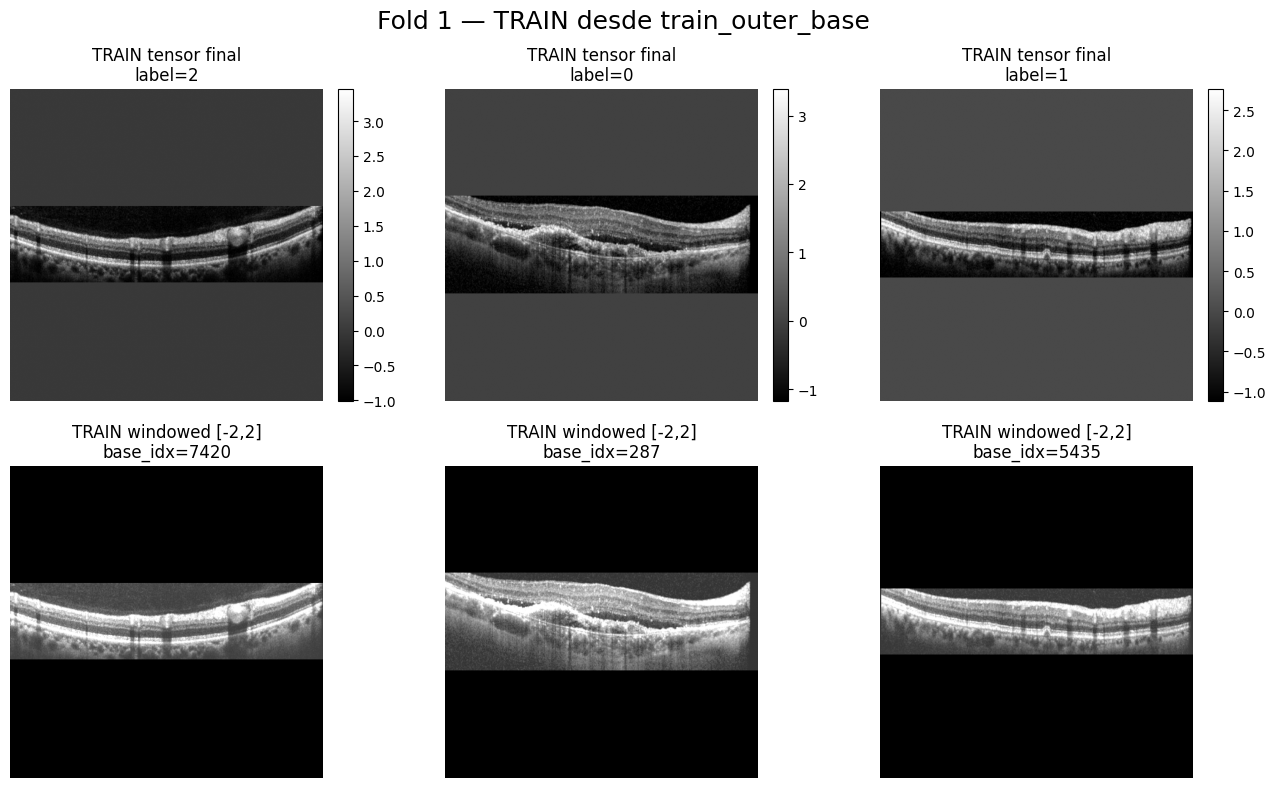

------------------------------------------------------------------------------------------
Fold 1 | VAL | muestra 1/3
base_idx      : 8269
image_path    : NEH_UT_2021RetinalOCTDataset\NORMAL/59/004_Normal.tif
label_id csv  : 2
label_id npy  : 2
shard_id      : 16
shard_pos     : 77
roi_shape     : (175, 768)
valid_pixels  : 59904
------------------------------------------------------------------------------------------
Fold 1 | VAL | muestra 2/3
base_idx      : 1712
image_path    : NEH_UT_2021RetinalOCTDataset\CNV/49/005_CNV.tif
label_id csv  : 0
label_id npy  : 0
shard_id      : 3
shard_pos     : 176
roi_shape     : (348, 768)
valid_pixels  : 118784
------------------------------------------------------------------------------------------
Fold 1 | VAL | muestra 3/3
base_idx      : 2779
image_path    : NEH_UT_2021RetinalOCTDataset\DRUSEN/106/OD/008_Drusen.tif
label_id csv  : 1
label_id npy  : 1
shard_id      : 5
shard_pos     : 219
roi_shape     : (220, 768)
valid_pixels  : 75264


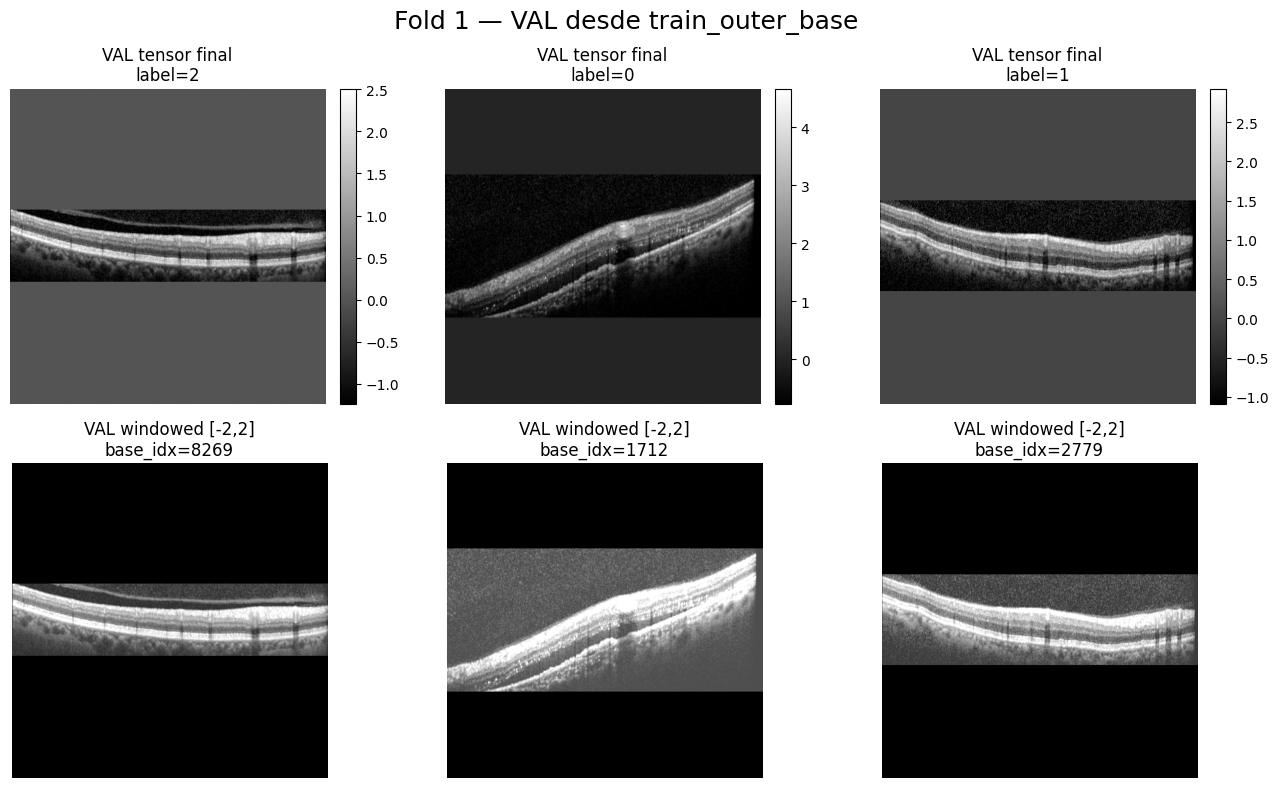

🔎 VALIDACIÓN ESTRUCTURAL — FOLD 2
train_idx shape : (8214,)
val_idx shape   : (1914,)
train_idx dtype : int64
val_idx dtype   : int64
train min/max   : 0 / 10127
val min/max     : 120 / 10034
Overlap train/val por base_idx: 0
Overlap train/val por group_id: 0
------------------------------------------------------------------------------------------
Fold 2 | TRAIN | muestra 1/3
base_idx      : 6316
image_path    : NEH_UT_2021RetinalOCTDataset\NORMAL/114/019_Normal.tif
label_id csv  : 2
label_id npy  : 2
shard_id      : 12
shard_pos     : 172
roi_shape     : (322, 768)
valid_pixels  : 110080
------------------------------------------------------------------------------------------
Fold 2 | TRAIN | muestra 2/3
base_idx      : 816
image_path    : NEH_UT_2021RetinalOCTDataset\CNV/139/010_CNV.tif
label_id csv  : 0
label_id npy  : 0
shard_id      : 1
shard_pos     : 304
roi_shape     : (189, 768)
valid_pixels  : 64512
---------------------------------------------------------------------------

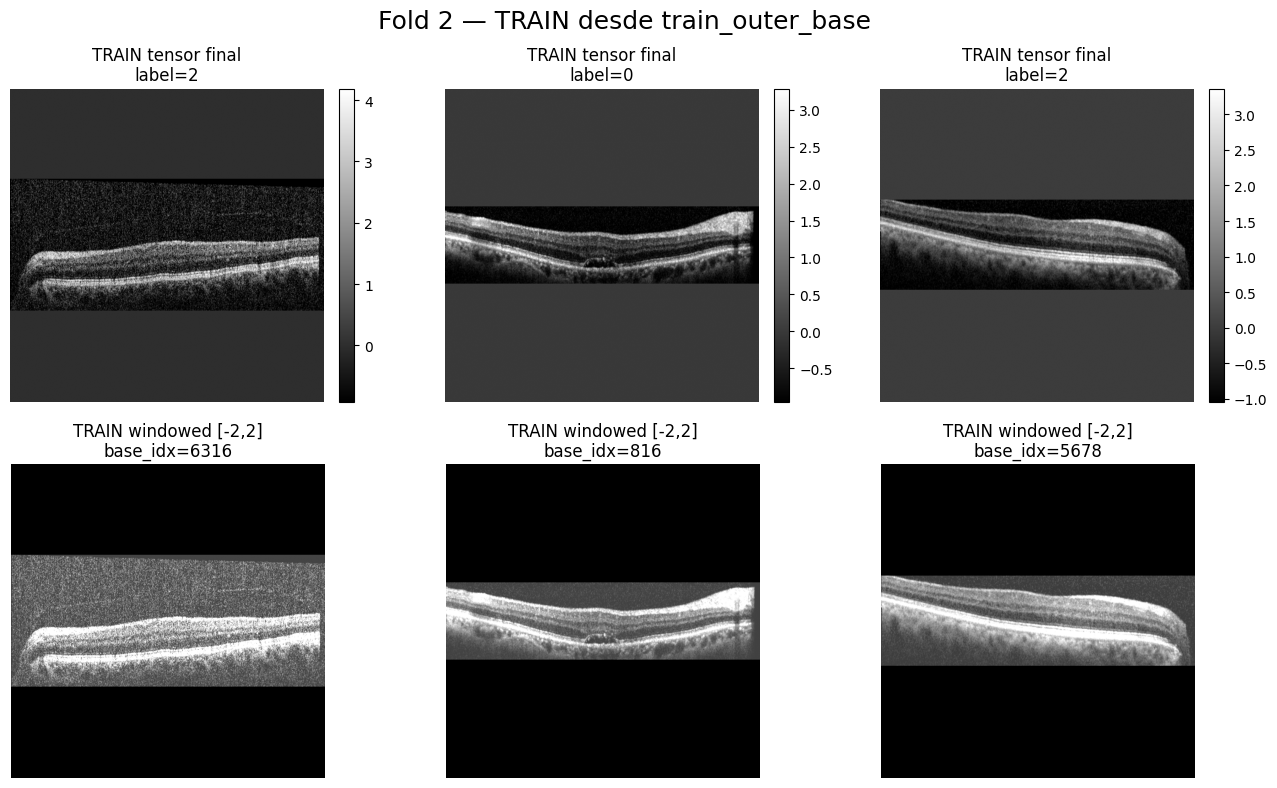

------------------------------------------------------------------------------------------
Fold 2 | VAL | muestra 1/3
base_idx      : 5591
image_path    : NEH_UT_2021RetinalOCTDataset\NORMAL/1/OS/017_normal.jpg
label_id csv  : 2
label_id npy  : 2
shard_id      : 10
shard_pos     : 471
roi_shape     : (496, 768)
valid_pixels  : 169472
------------------------------------------------------------------------------------------
Fold 2 | VAL | muestra 2/3
base_idx      : 3731
image_path    : NEH_UT_2021RetinalOCTDataset\DRUSEN/152/012_Drusen.tif
label_id csv  : 1
label_id npy  : 1
shard_id      : 7
shard_pos     : 147
roi_shape     : (308, 768)
valid_pixels  : 104960
------------------------------------------------------------------------------------------
Fold 2 | VAL | muestra 3/3
base_idx      : 2850
image_path    : NEH_UT_2021RetinalOCTDataset\DRUSEN/108/029_Drusen.tif
label_id csv  : 1
label_id npy  : 1
shard_id      : 5
shard_pos     : 290
roi_shape     : (202, 768)
valid_pixels  : 691

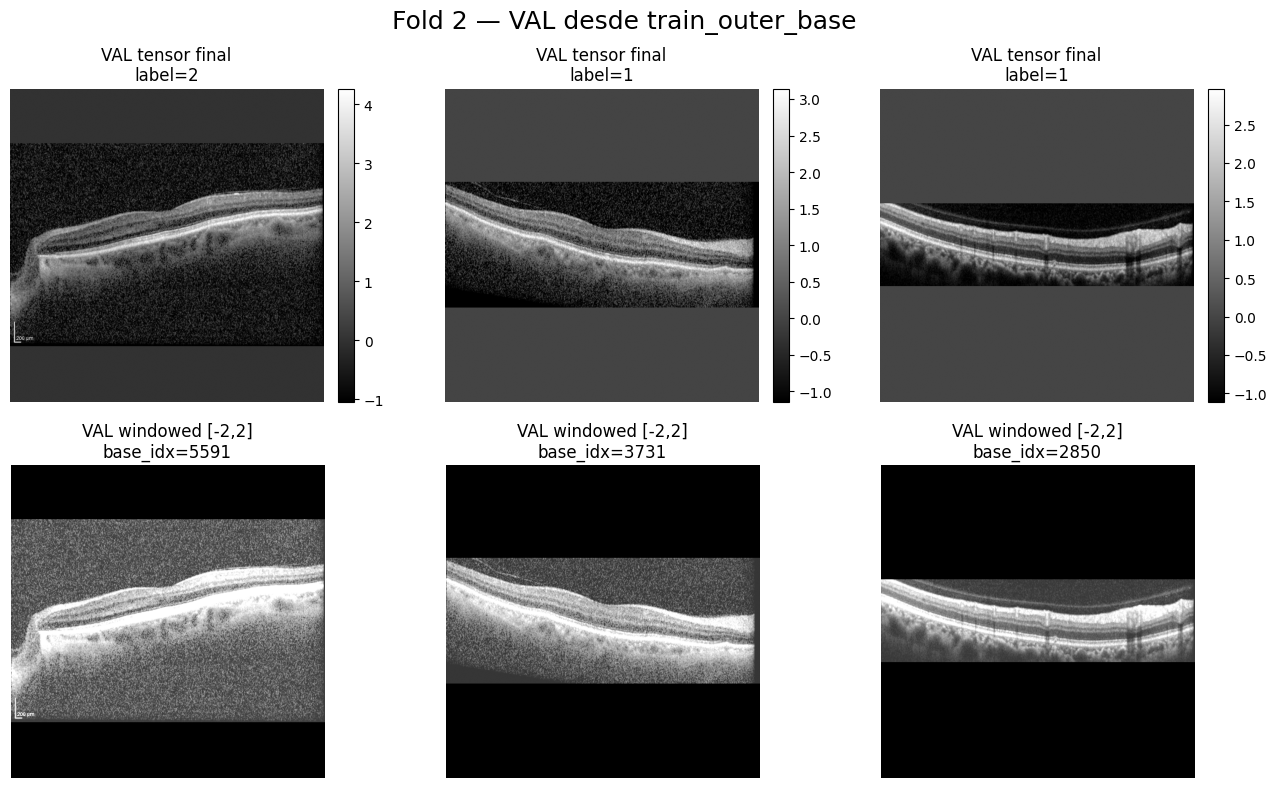

In [31]:
def load_base_shards(split_dir, split_name):
    """
    Carga las rutas de shards X/y de un split base.
    """
    split_dir = Path(split_dir)

    x_files = sorted(split_dir.glob(f"{split_name}_X_*.npy"))
    y_files = sorted(split_dir.glob(f"{split_name}_y_*.npy"))

    assert len(x_files) > 0, f"No se encontraron shards X para {split_name}"
    assert len(y_files) > 0, f"No se encontraron shards y para {split_name}"
    assert len(x_files) == len(y_files), f"Número desigual de shards X/y para {split_name}"

    return x_files, y_files


def load_train_base_index():
    """
    Carga el índice maestro de train_outer_base.
    """
    index_csv = TRAIN_BASE_DIR / "train_outer_base_index.csv"
    assert index_csv.exists(), f"No existe {index_csv}"
    return pd.read_csv(index_csv)


def get_sample_from_base_idx(base_idx, df_base_index, x_files, y_files):
    """
    Recupera una muestra desde train_outer_base a partir de base_idx.
    """
    row = df_base_index.iloc[int(base_idx)]

    shard_id = int(row["shard_id"])
    shard_pos = int(row["shard_pos"])

    X = np.load(x_files[shard_id], mmap_mode="r")
    y = np.load(y_files[shard_id], mmap_mode="r")

    x = X[shard_pos]   # [1, 512, 512]
    label = y[shard_pos]

    return x, label, row.to_dict()


def reconstruct_valid_mask_from_row(row):
    """
    Reconstruye la máscara válida del letterbox a partir de roi_shape
    y tamaño de salida fijo.
    """
    roi_shape = row["roi_shape"]
    if isinstance(roi_shape, str):
        roi_shape = roi_shape.strip("()")
        h, w = [int(v.strip()) for v in roi_shape.split(",")]
    else:
        # fallback defensivo
        h, w = IMG_SIZE, IMG_SIZE

    scale = min(IMG_SIZE / w, IMG_SIZE / h)
    new_h = max(1, int(round(h * scale)))
    new_w = max(1, int(round(w * scale)))

    top = (IMG_SIZE - new_h) // 2
    left = (IMG_SIZE - new_w) // 2

    valid_mask = np.zeros((IMG_SIZE, IMG_SIZE), dtype=bool)
    valid_mask[top:top + new_h, left:left + new_w] = True
    return valid_mask


def inspect_fold_indices(fold_id, df_base_index, x_files, y_files, indices_dir):
    """
    Inspección estructural de un fold.
    """
    train_idx_path = Path(indices_dir) / f"fold_{fold_id}_train_idx.npy"
    val_idx_path   = Path(indices_dir) / f"fold_{fold_id}_val_idx.npy"

    assert train_idx_path.exists(), f"No existe {train_idx_path}"
    assert val_idx_path.exists(),   f"No existe {val_idx_path}"

    train_idx = np.load(train_idx_path)
    val_idx   = np.load(val_idx_path)

    print("=" * 90)
    print(f"🔎 VALIDACIÓN ESTRUCTURAL — FOLD {fold_id}")
    print("=" * 90)
    print(f"train_idx shape : {train_idx.shape}")
    print(f"val_idx shape   : {val_idx.shape}")
    print(f"train_idx dtype : {train_idx.dtype}")
    print(f"val_idx dtype   : {val_idx.dtype}")
    print(f"train min/max   : {train_idx.min()} / {train_idx.max()}")
    print(f"val min/max     : {val_idx.min()} / {val_idx.max()}")

    assert train_idx.dtype == np.int64, "train_idx debe ser int64"
    assert val_idx.dtype == np.int64, "val_idx debe ser int64"

    assert len(np.unique(train_idx)) == len(train_idx), "train_idx contiene duplicados"
    assert len(np.unique(val_idx)) == len(val_idx), "val_idx contiene duplicados"

    overlap = len(set(train_idx.tolist()) & set(val_idx.tolist()))
    print(f"Overlap train/val por base_idx: {overlap}")
    assert overlap == 0, f"Fold {fold_id}: hay overlap entre train y val"

    # chequeo por group_id si existe
    if "group_id" in df_base_index.columns:
        train_groups = set(df_base_index.iloc[train_idx]["group_id"].astype(str))
        val_groups   = set(df_base_index.iloc[val_idx]["group_id"].astype(str))
        group_overlap = len(train_groups & val_groups)
        print(f"Overlap train/val por group_id: {group_overlap}")
        assert group_overlap == 0, f"Fold {fold_id}: hay overlap por group_id"

    return train_idx, val_idx


def visualize_fold_samples(
    fold_id,
    subset_name,
    subset_idx,
    df_base_index,
    x_files,
    y_files,
    n_samples=3,
    random_samples=True
):
    """
    Visualiza muestras de TRAIN o VAL recuperadas desde train_outer_base
    usando los índices del fold.
    """
    assert subset_name in ["TRAIN", "VAL"]

    if random_samples:
        chosen = np.random.choice(subset_idx, size=min(n_samples, len(subset_idx)), replace=False)
    else:
        chosen = subset_idx[:min(n_samples, len(subset_idx))]

    chosen = np.array(chosen, dtype=np.int64)

    fig, axes = plt.subplots(2, len(chosen), figsize=(4.4 * len(chosen), 8))
    if len(chosen) == 1:
        axes = np.array(axes).reshape(2, 1)

    fig.suptitle(f"Fold {fold_id} — {subset_name} desde train_outer_base", fontsize=18, y=0.98)

    for j, base_idx in enumerate(chosen):
        x, y, row = get_sample_from_base_idx(base_idx, df_base_index, x_files, y_files)

        z_img = x[0]
        valid_mask = reconstruct_valid_mask_from_row(row)
        z_vis = denorm_for_display(z_img, valid_mask=valid_mask, vmin=-2.0, vmax=2.0)

        im0 = axes[0, j].imshow(z_img, cmap="gray")
        axes[0, j].set_title(f"{subset_name} tensor final\nlabel={int(y)}", fontsize=12)
        axes[0, j].axis("off")
        plt.colorbar(im0, ax=axes[0, j], fraction=0.046, pad=0.04)

        axes[1, j].imshow(z_vis, cmap="gray", vmin=0.0, vmax=1.0)
        axes[1, j].set_title(f"{subset_name} windowed [-2,2]\nbase_idx={int(base_idx)}", fontsize=12)
        axes[1, j].axis("off")

        print("-" * 90)
        print(f"Fold {fold_id} | {subset_name} | muestra {j+1}/{len(chosen)}")
        print(f"base_idx      : {int(base_idx)}")
        print(f"image_path    : {row['image_path']}")
        print(f"label_id csv  : {row['label_id']}")
        print(f"label_id npy  : {int(y)}")
        print(f"shard_id      : {row['shard_id']}")
        print(f"shard_pos     : {row['shard_pos']}")
        print(f"roi_shape     : {row['roi_shape']}")
        print(f"valid_pixels  : {row['valid_pixels']}")

        assert int(row["label_id"]) == int(y), "Etiqueta inconsistente entre CSV y shard"

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Cargar recursos base
# ------------------------------------------------------------
df_train_base_index = load_train_base_index()
train_x_files, train_y_files = load_base_shards(TRAIN_BASE_DIR, "train_outer")

# ------------------------------------------------------------
# Elegir folds a validar
# Puedes cambiar la lista si quieres inspeccionar más
# ------------------------------------------------------------
folds_to_validate = [1, 2]

for fold_id in folds_to_validate:
    train_idx, val_idx = inspect_fold_indices(
        fold_id=fold_id,
        df_base_index=df_train_base_index,
        x_files=train_x_files,
        y_files=train_y_files,
        indices_dir=INDICES_DIR
    )

    visualize_fold_samples(
        fold_id=fold_id,
        subset_name="TRAIN",
        subset_idx=train_idx,
        df_base_index=df_train_base_index,
        x_files=train_x_files,
        y_files=train_y_files,
        n_samples=3,
        random_samples=True
    )

    visualize_fold_samples(
        fold_id=fold_id,
        subset_name="VAL",
        subset_idx=val_idx,
        df_base_index=df_train_base_index,
        x_files=train_x_files,
        y_files=train_y_files,
        n_samples=3,
        random_samples=True
    )